# OseGold Ride-Request Demand Forecasting for Bike Rides in Lagos, Nigeria
### Predicting how many ride requests an area will receive at a given military hour

**Problem.** Ride requests are hard to serve because they are unpredictable and spontaneous. A system that forecasts the approximate number of rides in the near future lets an operator **manage its fleet: put enough bikes in each area before the requests arrive** (Section 3.8). This project predicts **the ride-request demand for a particular area at a given time**. An **area** is identified by **latitude and longitude values**, and the **time** is a duration measured in **military (24-hour) hours**, for example 0800 hrs or 1800 hrs.

**Dataset fields used:** user_ID, request_latitude, request_longitude, request_time, pickup location, drop location.

**Simplifying assumptions applied to the data (Section 1.3):**
1. **One request per area per hour.** Multiple requests from the same area (the same unique latitude-longitude) in an hour count as one request.
2. **Eight-minute rule.** Subsequent requests under 8 minutes after a user's first request are ignored, whatever area they come from.
3. **Fraud filter.** If the pickup and drop locations are under 50 metres apart, the request is treated as fraud and ignored.

| Phase | What happens |
|---|---|
| **1. Data cleaning, analysis and visualization** | Clean the records, apply the three assumptions, add real Lagos weather, explore demand patterns |
| **2. Data clustering and model building** | K-means groups request locations into areas; build the area-by-military-hour demand table with features |
| **3. Evaluating model approaches** | Compare forecasting models, pick the best, predict demand for any area and hour, test Lagos what-if scenarios, **turn forecasts into fleet allocation** |
| **4. Presentation** | Why demand forecasting matters for bike-ride companies in Nigeria and Africa |

---
## READ FIRST: where the data comes from

The objectives ask for data from an open repository with these fields. I searched for one (October 2026). No open repository publishes ride-request data that includes **user_ID** for a Nigerian city. Companies such as Bolt and the former Uber Nigeria (Uber ended ride-hailing in Nigeria on 2 September 2026) keep rider-level data private, and open taxi and bike-share datasets elsewhere remove user identifiers to protect privacy. Chowdeck, Glovo and GIG Logistics also publish no order data.

**So this notebook:**
1. Uses **real Lagos hourly weather** from Open-Meteo (an open data source) and **real Lagos district locations**.
2. **Simulates the ride requests** in exactly the required format. The simulator is a transparent "digital twin" of Lagos bike rides: every behaviour is a named setting (Section 0.2) marked as sourced from reporting or assumed. **Results from simulated data reflect those assumptions; they are not measurements of any company.**
3. **Exports the dataset as a CSV** (Section 0.5) so it can publish it to an open repository (GitHub, Kaggle, Zenodo or Hugging Face), which makes the project data openly available as the objectives require.
4. Lets you **plug in real data**: set **REAL_DATA_PATH** (Section 0.2) to a CSV with the same fields and everything runs unchanged.

**Nigeria and Africa factors built into the simulator (sources in Section 3.6):** seasonal rain and flooding, bad roads, poor street naming and house numbering, agbero levies, local-government and traffic officials, police stops, public holidays, payday and the December season. When riders are delayed, stopped or cannot find an address, customers cancel and **re-request within minutes**; the eight-minute rule removes exactly these repeats, so one can see how much friction inflates raw request counts.

Normal Colab runtime was used (no GPU needed). Total run time is roughly 10 to 15 minutes.

## 0. Setup

In [28]:
import warnings, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("Setup complete")

Setup complete


## 0.2 Configuration and assumptions (these can be editted later with real field data)
Values marked **SOURCED** are inspired by figures in news reporting (links in Section 3.6). **ASSUMED** values are my illustrative guesses and are not measured anywhere. Replace them with real field data when it is available.

In [29]:
# ------------------------------------------------------------------ data source switch
REAL_DATA_PATH = None        # CSV with columns: user_ID, request_latitude, request_longitude, request_time,
                             #                   pickup_lat, pickup_lng, drop_lat, drop_lng.   None = use the simulator
YEAR = 2025                  # year simulated and used for Lagos weather
REQUESTS_PER_AREA_HOUR = 1.6 # ASSUMED average raw ride requests per district per hour (pilot scale)
LAGOS = (6.5244, 3.3792)     # latitude, longitude for the weather download

# ------------------------------------------------------------------ the three simplifying assumptions of the project
AREA_PRECISION = 3           # decimals kept in lat/lng to define a "unique area" (3 decimals is about 110 m)
REPEAT_MINUTES = 8           # requests by the same user under 8 minutes after their first request are ignored
FRAUD_METRES = 50            # pickup and drop closer than 50 m are treated as fraud and ignored
REPEAT_RULE_SCOPE = "user"   # "user" = per user_ID (regardless of the area of origin); "global" = any user (removes most data; not recommended)

# ------------------------------------------------------------------ Nigerian public holidays 2025 (approximate; Eid dates depend on moon sighting; verify)
HOLIDAYS = ["2025-01-01", "2025-03-31", "2025-04-01", "2025-04-18", "2025-04-21", "2025-05-01",
            "2025-06-06", "2025-06-09", "2025-06-12", "2025-09-05", "2025-10-01", "2025-12-25", "2025-12-26"]

# ------------------------------------------------------------------ Lagos districts (locations are real and approximate; the 0 to 1.2 scores are ASSUMED, NOT measurements)
#   ride_w : relative bike-ride demand;  flood : 1 = low-lying or flood-prone in heavy rain
#   agbero / lga / police : intensity of agbero encounters, local-government and traffic officials, and police stops
#   addr_q : street-address quality (1 = easy to find);  road_q : road condition (1 = good)
#   weekend : weekend demand as a share of weekday demand;  leisure : weight of an afternoon leisure peak (beach, parks, shopping)
ZONE_COLS = ["district", "lat", "lng", "ride_w", "flood", "agbero", "lga", "police", "addr_q", "road_q", "weekend", "leisure"]
ZONES = pd.DataFrame([
    ("Ikeja",            6.6018, 3.3515, 0.8, 0, 0.50, 0.60, 0.50, 0.75, 0.75, 0.30, 0.10),
    ("Yaba",             6.5095, 3.3711, 0.9, 0, 0.60, 0.60, 0.50, 0.70, 0.70, 0.40, 0.20),
    ("Surulere",         6.5011, 3.3568, 0.8, 0, 0.60, 0.50, 0.50, 0.65, 0.65, 0.50, 0.20),
    ("Victoria Island",  6.4281, 3.4219, 0.6, 1, 0.20, 0.30, 0.50, 0.92, 0.90, 0.35, 0.30),
    ("Ikoyi",            6.4549, 3.4346, 0.4, 1, 0.15, 0.30, 0.50, 0.90, 0.90, 0.50, 0.40),
    ("Lekki Phase 1",    6.4478, 3.4723, 0.6, 1, 0.30, 0.40, 0.40, 0.85, 0.80, 0.90, 0.90),
    ("Ajah",             6.4698, 3.5852, 0.9, 1, 0.80, 0.70, 0.50, 0.55, 0.60, 0.70, 0.50),
    ("Ikorodu",          6.6194, 3.5105, 1.0, 1, 1.00, 0.80, 0.60, 0.50, 0.55, 0.65, 0.30),
    ("Ikotun / Egbeda",  6.5517, 3.2681, 1.1, 0, 1.10, 0.90, 0.60, 0.45, 0.50, 0.65, 0.30),
    ("Apapa",            6.4489, 3.3592, 0.5, 1, 0.90, 0.80, 0.70, 0.60, 0.45, 0.30, 0.10),
    ("Oshodi",           6.5550, 3.3430, 1.2, 0, 1.20, 1.00, 0.80, 0.50, 0.60, 0.45, 0.20),
    ("Maryland",         6.5670, 3.3640, 0.7, 0, 0.70, 0.60, 0.60, 0.70, 0.70, 0.40, 0.15),
    ("Gbagada",          6.5560, 3.3870, 0.9, 0, 0.60, 0.50, 0.50, 0.60, 0.65, 0.55, 0.25),
    ("Lagos Island",     6.4550, 3.3940, 0.5, 1, 0.90, 1.00, 0.70, 0.55, 0.55, 0.30, 0.15),
    ("Mushin",           6.5290, 3.3550, 1.1, 0, 1.10, 0.90, 0.70, 0.45, 0.50, 0.55, 0.25),
], columns=ZONE_COLS)
print(f"{len(ZONES)} Lagos districts configured | data source: {'REAL FILE' if REAL_DATA_PATH else 'SIMULATOR'}")
ZONES[["district", "ride_w", "flood", "agbero", "lga", "police", "addr_q", "road_q"]]

15 Lagos districts configured | data source: SIMULATOR


,district,ride_w,flood,agbero,lga,police,addr_q,road_q
0,Ikeja,0.8,0,0.50,0.6,0.5,0.75,0.75
1,Yaba,0.9,0,0.60,0.6,0.5,0.70,0.70
2,Surulere,0.8,0,0.60,0.5,0.5,0.65,0.65
3,Victoria Island,0.6,1,0.20,0.3,0.5,0.92,0.90
4,Ikoyi,0.4,1,0.15,0.3,0.5,0.90,0.90
5,Lekki Phase 1,0.6,1,0.30,0.4,0.4,0.85,0.80
6,Ajah,0.9,1,0.80,0.7,0.5,0.55,0.60
7,Ikorodu,1.0,1,1.00,0.8,0.6,0.50,0.55
8,Ikotun / Egbeda,1.1,0,1.10,0.9,0.6,0.45,0.50
9,Apapa,0.5,1,0.90,0.8,0.7,0.60,0.45


## 0.3 Lagos weather (real data)
Real hourly Lagos weather from Open-Meteo. If the service cannot be reached, a **synthetic Lagos-style climate** (afternoon showers, rainy season peaking in June) is used and the notebook says so.

In [30]:
def get_weather(start, end):
    r = requests.get("https://archive-api.open-meteo.com/v1/archive", timeout=60, params=dict(
        latitude=LAGOS[0], longitude=LAGOS[1], start_date=start, end_date=end, timezone="Africa/Lagos",
        hourly="temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m"))
    r.raise_for_status()
    w = pd.DataFrame(r.json()["hourly"]); w["time"] = pd.to_datetime(w["time"])
    return w.rename(columns={"time": "hour_ts", "temperature_2m": "temp_c", "relative_humidity_2m": "humidity",
                             "precipitation": "precip_mm", "wind_speed_10m": "wind_kmh"})

def synthetic_weather(start, end, seed=0):
    p_month = {1: .01, 2: .02, 3: .05, 4: .09, 5: .13, 6: .20, 7: .14, 8: .09, 9: .15, 10: .13, 11: .05, 12: .01}
    r = np.random.default_rng(seed)
    t = pd.date_range(start, pd.Timestamp(end) + pd.Timedelta(hours=23), freq="h")
    p = t.month.map(p_month).values * np.where((t.hour >= 14) & (t.hour <= 21), 2.0, 0.6)
    rain = np.where(r.random(len(t)) < p, r.gamma(1.6, 2.2, len(t)), 0.0)
    return pd.DataFrame({"hour_ts": t, "temp_c": 28 + 3 * np.sin((t.hour - 9) / 24 * 2 * np.pi),
                         "humidity": r.uniform(65, 92, len(t)), "precip_mm": rain, "wind_kmh": r.uniform(2, 18, len(t))})

if REAL_DATA_PATH:
    _real = pd.read_csv(REAL_DATA_PATH, parse_dates=["request_time"])
    W_START, W_END = _real.request_time.min().strftime("%Y-%m-%d"), _real.request_time.max().strftime("%Y-%m-%d")
else:
    W_START, W_END = f"{YEAR}-01-01", f"{YEAR}-12-31"
try:
    weather = get_weather(W_START, W_END); WEATHER_SOURCE = "REAL (Open-Meteo, Lagos)"
except Exception:
    weather = synthetic_weather(W_START, W_END); WEATHER_SOURCE = "SYNTHETIC Lagos-style climate (real weather download failed)"
weather["hour_ts"] = pd.to_datetime(weather["hour_ts"])
WEATHER_COLS = ["temp_c", "humidity", "precip_mm", "wind_kmh"]
print("Weather source:", WEATHER_SOURCE)
print(f"Hours: {len(weather):,} | rainy hours (>0.5 mm): {int((weather.precip_mm > 0.5).sum())} | heavy-rain hours (>=3 mm): {int((weather.precip_mm >= 3).sum())}")

Weather source: REAL (Open-Meteo, Lagos)
Hours: 8,760 | rainy hours (>0.5 mm): 637 | heavy-rain hours (>=3 mm): 125


## 0.4 The Lagos ride-request simulator
Each row is one ride request with the required fields. What it does:
- **Demand** follows commuter rush hours (with area-specific weekend and afternoon-leisure patterns), rain (fewer bike rides in rain), public holidays, payday weeks and December.
- **Users** have IDs; a few heavy users request often. Requests start from **popular spots** (motor parks, markets, junctions) as well as from anywhere in the district.
- **Request location vs pickup location:** the request is where the app was opened (GPS); the pickup is the pin the user chose. Poor street addresses make them differ more.
- **Re-requests:** when a rider cancels, gets stopped or cannot find the address (more likely with agbero, official and police stops, bad roads, poor addresses and heavy rain), the user **requests again within a few minutes**, sometimes from a different spot.
- **Fraud:** about 1% of requests have a drop point within 50 m of the pickup (for example, fake rides to claim incentives) (ASSUMED).
- **Data problems:** duplicated app events, missing fields, GPS errors at (0, 0).

In [31]:
def simulate_requests(weather, seed=SEED, agbero_mult=1.0, lga_mult=1.0, police_mult=1.0,
                      addr_boost=0.0, road_boost=0.0, demand_mult=1.0, storm_hours=None, storm_mm=4.0, dirty=True):
    rng = np.random.default_rng(seed)
    t = pd.date_range(f"{YEAR}-01-01", f"{YEAR}-12-31 23:00", freq="h")
    W = weather.drop_duplicates("hour_ts").set_index("hour_ts").reindex(t).ffill().bfill()
    rain = W.precip_mm.values.copy()
    hr, dow, month, day = t.hour.values, t.dayofweek.values, t.month.values, t.day.values
    if storm_hours:                                       # what-if: heavy showers at these hours every day
        rain = np.where(np.isin(hr, storm_hours), np.maximum(rain, storm_mm), rain)
    weekend = dow >= 5
    hol = np.asarray(t.normalize().isin(pd.to_datetime(HOLIDAYS)))
    nz, nh = len(ZONES), len(t)

    # ---- demand: commuter peaks around 0800 and 1800 hrs (ASSUMED), weekends flatter ----
    commute = 0.08 + np.exp(-((hr - 7.8) / 1.5) ** 2) + 1.2 * np.exp(-((hr - 17.8) / 1.8) ** 2)
    leisure = np.exp(-((hr - 14.5) / 3.0) ** 2)
    wk = np.where(weekend[None, :], ZONES.weekend.values[:, None], 1.0)               # each area has its own weekend pattern
    prof = wk * (commute[None, :] + ZONES.leisure.values[:, None] * leisure[None, :])
    mod, heavy = (rain >= 0.5) & (rain < 3), rain >= 3
    mult = (1 - 0.30 * mod - 0.55 * heavy) * (1 - 0.4 * hol) * (1 + 0.10 * (day >= 25)) * (1 + 0.10 * (month == 12))
    base = ZONES.ride_w.values[:, None] * prof
    scale = REQUESTS_PER_AREA_HOUR * nz * nh / base.sum()
    cnt = rng.poisson(base * mult[None, :] * scale * demand_mult)
    z_i, h_i = np.nonzero(cnt)
    reps = cnt[z_i, h_i]
    z, h = np.repeat(z_i, reps), np.repeat(h_i, reps)
    n = len(z)

    addr_q = np.clip(ZONES.addr_q.values + addr_boost, 0.2, 0.99)[z]
    road_q = np.clip(ZONES.road_q.values + road_boost, 0.3, 0.99)[z]
    lat_c, lng_c = ZONES.lat.values[z], ZONES.lng.values[z]

    # ---- users: heavy-tailed activity; 90% of requests come from the district's own users ----
    POOL = 4000
    home = np.where(rng.random(n) < 0.90, z, rng.integers(0, nz, n))
    rank = np.minimum((POOL * rng.random(n) ** 3).astype(int), POOL - 1)
    user = home * POOL + rank

    # ---- pickup pin: popular spots (65%) or anywhere in the district (35%) ----
    NH = 6
    hot = np.random.default_rng(123).normal(0, 0.008, (nz, NH, 2))
    hw = 1 / (np.arange(NH) + 1) ** 1.2; hw /= hw.sum()
    use_hot = rng.random(n) < 0.65
    hk = rng.choice(NH, n, p=hw)
    pin_lat = np.where(use_hot, lat_c + hot[z, hk, 0] + rng.normal(0, 0.0003, n), lat_c + rng.normal(0, 0.011, n))
    pin_lng = np.where(use_hot, lng_c + hot[z, hk, 1] + rng.normal(0, 0.0003, n), lng_c + rng.normal(0, 0.011, n))
    gps_sd = 0.0004 + 0.0012 * (1 - addr_q)                 # request GPS vs chosen pin: worse where addresses are poor
    req_lat, req_lng = pin_lat + gps_sd * rng.standard_normal(n), pin_lng + gps_sd * rng.standard_normal(n)

    # ---- trip: distance, drop point; about 1% fraud with a drop point within 50 m ----
    dist = np.clip(np.exp(np.log(4.5) + 0.55 * rng.standard_normal(n)), 0.5, 25)
    fraud = rng.random(n) < 0.01
    dist = np.where(fraud, rng.uniform(0.002, 0.045, n), dist)
    th = rng.uniform(0, 2 * np.pi, n)
    drop_lat = pin_lat + dist * np.cos(th) / 110.57
    drop_lng = pin_lng + dist * np.sin(th) / (111.32 * np.cos(np.radians(pin_lat)))
    created = t[h] + pd.to_timedelta(rng.uniform(0, 59.99, n), unit="m")

    # ---- re-requests: friction, bad roads, poor addresses and heavy rain make riders cancel, so users ask again ----
    fr = (ZONES.agbero.values * agbero_mult + ZONES.lga.values * lga_mult + ZONES.police.values * police_mult)[z] / 3
    rain_o = rain[h]
    p_rep = np.clip(0.04 + 0.10 * np.minimum(fr, 1.5) + 0.08 * (1 - road_q) + 0.06 * (1 - addr_q)
                    + 0.10 * (rain_o >= 3) + 0.04 * ((rain_o >= 0.5) & (rain_o < 3)), 0, 0.5)
    parts = [dict(user=user, t=created, rl=req_lat, rg=req_lng, pl=pin_lat, pg=pin_lng, dl=drop_lat, dg=drop_lng, rep=np.zeros(n, int), fraud=fraud.astype(int))]
    cur, cur_p = parts[0], p_rep
    for _ in range(2):                                     # up to two chained re-requests
        sel = rng.random(len(cur["user"])) < cur_p
        k = int(sel.sum())
        if k == 0: break
        delay = np.where(rng.random(k) < 0.85, rng.uniform(1, 7.5, k), rng.uniform(8, 25, k))   # minutes
        moved = rng.random(k) < 0.25                        # 25% walk to a different pickup spot
        ang = rng.uniform(0, 2 * np.pi, k); rad = np.where(moved, rng.uniform(0.3, 0.8, k), 0.03) / 111.0
        new = dict(user=cur["user"][sel], t=cur["t"][sel] + pd.to_timedelta(delay, unit="m"),
                   rl=cur["rl"][sel] + rad * np.cos(ang), rg=cur["rg"][sel] + rad * np.sin(ang),
                   pl=cur["pl"][sel] + rad * np.cos(ang), pg=cur["pg"][sel] + rad * np.sin(ang),
                   dl=cur["dl"][sel], dg=cur["dg"][sel], rep=np.ones(k, int), fraud=cur["fraud"][sel])
        parts.append(new); cur, cur_p = new, np.full(k, 0.30)

    cat = lambda key: np.concatenate([p[key] for p in parts])
    d = pd.DataFrame({
        "user_ID": ["U" + str(u).zfill(6) for u in cat("user")],
        "request_latitude": cat("rl"), "request_longitude": cat("rg"),
        "request_time": pd.DatetimeIndex(np.concatenate([np.asarray(p["t"]) for p in parts])),
        "pickup_lat": cat("pl"), "pickup_lng": cat("pg"), "drop_lat": cat("dl"), "drop_lng": cat("dg"),
        "sim_is_repeat": cat("rep"), "sim_is_fraud": cat("fraud"),     # hidden labels, used only to audit the rules
    }).sort_values("request_time").reset_index(drop=True)
    if not dirty:
        return d

    # ---- realistic data problems (ASSUMED rates; weak GPS and mobile networks cause them) ----
    k = len(d); raw = d.copy()
    i = rng.choice(k, int(0.004 * k), replace=False); raw.loc[raw.index[i], ["request_latitude", "request_longitude"]] = 0.0
    i = rng.choice(k, int(0.005 * k), replace=False); raw.loc[raw.index[i], ["drop_lat", "drop_lng"]] = np.nan
    i = rng.choice(k, int(0.002 * k), replace=False); raw.loc[raw.index[i], "request_time"] = pd.NaT
    raw = pd.concat([raw, d.sample(int(0.003 * k), random_state=seed)], ignore_index=True)       # duplicated app events
    return raw

print("Simulator ready")

Simulator ready


---
# PHASE 1: Data Cleaning, Analysis and Visualization

## 1.1 Load the ride requests

In [32]:
REQUIRED = ["user_ID", "request_latitude", "request_longitude", "request_time", "pickup_lat", "pickup_lng", "drop_lat", "drop_lng"]
if REAL_DATA_PATH:
    raw = _real.copy()
    miss = [c for c in REQUIRED if c not in raw.columns]
    assert not miss, f"Your file is missing required columns: {miss}"
    for c in ["sim_is_repeat", "sim_is_fraud"]:
        if c not in raw.columns: raw[c] = np.nan
    DATA_SOURCE = "REAL"
else:
    raw = simulate_requests(weather)
    DATA_SOURCE = "SIMULATED"
print(f"DATA SOURCE: {DATA_SOURCE} | {len(raw):,} ride-request records | {raw.user_ID.nunique():,} users")
raw[REQUIRED].head()

DATA SOURCE: SIMULATED | 250,801 ride-request records | 49,675 users


,user_ID,request_latitude,request_longitude,request_time,pickup_lat,pickup_lng,drop_lat,drop_lng
0,U032832,6.570257,3.261458,2025-01-01 00:48:29.127240924,6.570952,3.262962,6.477127,3.263248
1,U016090,6.455418,3.434045,2025-01-01 00:50:02.831835618,6.455686,3.434464,6.362818,3.393572
2,U032832,6.572785,3.268069,2025-01-01 00:59:36.928956035,6.573480,3.269572,6.477127,3.263248
3,U032832,6.572920,3.268303,2025-01-01 01:04:04.840706147,6.573616,3.269806,6.477127,3.263248
4,U012091,6.432765,3.443578,2025-01-01 02:39:36.821333190,6.432046,3.443270,6.488073,3.440754


## 0.5 Export the dataset so it can be published to an open repository
The objectives ask for data available from an open repository. This saves the raw dataset (only the required fields) as a CSV. Publish it on GitHub, Kaggle, Zenodo or Hugging Face with a short README that says **it is simulated**, lists the assumptions in Section 0.2, and credits Open-Meteo for the weather.

In [33]:
EXPORT = "lagos_ride_requests_simulated.csv" if DATA_SOURCE == "SIMULATED" else "ride_requests_export.csv"
raw[REQUIRED].to_csv(EXPORT, index=False)
print(f"Saved {EXPORT} ({os.path.getsize(EXPORT) / 1e6:.1f} MB, {len(raw):,} rows)")
try:
    from google.colab import files
    files.download(EXPORT)
except Exception:
    print("(Not running in Colab: find the file in the notebook's folder)")

Saved lagos_ride_requests_simulated.csv (36.9 MB, 250,801 rows)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [57]:
import os

file_path = "lagos_ride_requests_simulated.csv"

size_mb = os.path.getsize(file_path) / (1024 * 1024)

print(f"CSV file size: {size_mb:.2f} MB")

CSV file size: 35.21 MB


In [60]:
print(df.head())
print(df.columns.tolist())
print(df.shape)

   user_ID  request_latitude  request_longitude                  request_time  \
0  U032832          6.570257           3.261458 2025-01-01 00:48:29.127240924   
1  U016090          6.455418           3.434045 2025-01-01 00:50:02.831835618   
2  U032832          6.572785           3.268069 2025-01-01 00:59:36.928956035   
3  U012091          6.432765           3.443578 2025-01-01 02:39:36.821333190   
4  U022245          6.443646           3.468242 2025-01-01 02:40:21.967627428   

   pickup_lat  pickup_lng  drop_lat  drop_lng  sim_is_repeat  sim_is_fraud  \
0    6.570952    3.262962  6.477127  3.263248              0             0   
1    6.455686    3.434464  6.362818  3.393572              0             0   
2    6.573480    3.269572  6.477127  3.263248              1             0   
3    6.432046    3.443270  6.488073  3.440754              0             0   
4    6.443635    3.467436  6.477449  3.458272              0             0   

   ...  area_lat  area_lng             hour_

In [63]:
required_columns = [
    "user_ID",
    "request_latitude",
    "request_longitude",
    "request_time",
    "pickup_lat",
    "pickup_lng",
    "drop_lat",
    "drop_lng"
]

final_df = df[required_columns].copy()

print("Dataset shape:", final_df.shape)
print(final_df.head())

Dataset shape: (204691, 8)
   user_ID  request_latitude  request_longitude                  request_time  \
0  U032832          6.570257           3.261458 2025-01-01 00:48:29.127240924   
1  U016090          6.455418           3.434045 2025-01-01 00:50:02.831835618   
2  U032832          6.572785           3.268069 2025-01-01 00:59:36.928956035   
3  U012091          6.432765           3.443578 2025-01-01 02:39:36.821333190   
4  U022245          6.443646           3.468242 2025-01-01 02:40:21.967627428   

   pickup_lat  pickup_lng  drop_lat  drop_lng  
0    6.570952    3.262962  6.477127  3.263248  
1    6.455686    3.434464  6.362818  3.393572  
2    6.573480    3.269572  6.477127  3.263248  
3    6.432046    3.443270  6.488073  3.440754  
4    6.443635    3.467436  6.477449  3.458272  


In [64]:
final_df.to_csv(
    "lagos_ride_requests_simulated.csv",
    index=False
)

In [65]:
import os

final_df.to_csv(
    "lagos_ride_requests_simulated.csv.gz",
    index=False,
    compression="gzip"
)

size_mb = os.path.getsize(
    "lagos_ride_requests_simulated.csv.gz"
) / (1024 * 1024)

print(f"Compressed file size: {size_mb:.2f} MB")

Compressed file size: 12.26 MB


In [66]:
from google.colab import files

files.download("lagos_ride_requests_simulated.csv.gz")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [62]:
from google.colab import files

files.download("lagos_ride_requests_simulated.csv.gz")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
readme_content = """
# Simulated Weather Dataset

## Project Overview

This repository contains a simulated weather dataset prepared
for educational and data analysis purposes.

**Important:** This dataset is simulated and does not represent
a complete record of actual observed weather conditions.

## Dataset Information

- File: simulated_weather_data.csv
- Format: CSV
- Contents: Only the required dataset fields.
- Purpose: Data analysis and project exercises.

## Assumptions (Section 0.2)

1. [AREA_PRECISION = 3 ]          # decimals kept in lat/lng to define a "unique area" (3 decimals is about 110 m)
2. [REPEAT_MINUTES = 8]           # requests by the same user under 8 minutes after their first request are ignored
3. [FRAUD_METRES = 50 ]           # pickup and drop closer than 50 m are treated as fraud and ignored
4. [REPEAT_RULE_SCOPE = "user"]   # "user" = per user_ID (regardless of the area of origin); "global" = any user (removes most data; not recommended)

## Data Sources and Acknowledgements

Weather data credit: Open-Meteo.

Website: https://open-meteo.com/

## Disclaimer

This is a simulated dataset created for educational
and analytical purposes. It should not be interpreted
as verified real-world observations.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [55]:
from google.colab import files

files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 1.2 Clean the data
Poor mobile networks and GPS drift in Nigerian cities produce duplicated app events, missing fields and requests at (0, 0). Each problem is handled and counted.

In [35]:
def haversine_m(la1, lo1, la2, lo2):
    p = np.pi / 180
    a = np.sin((la2 - la1) * p / 2) ** 2 + np.cos(la1 * p) * np.cos(la2 * p) * np.sin((lo2 - lo1) * p / 2) ** 2
    return 12742000 * np.arcsin(np.sqrt(a))

log = [("Raw records", 0, len(raw))]
def step(name, before, after): log.append((name, len(before) - len(after), len(after)))

df = raw.copy()
df["request_time"] = pd.to_datetime(df.request_time)
d = df.drop_duplicates(["user_ID", "request_time", "request_latitude", "request_longitude"]); step("Duplicate app events", df, d); df = d
d = df.dropna(subset=REQUIRED);                                                  step("Missing user, time or locations", df, d); df = d
d = df[df.request_latitude.between(6.30, 6.80) & df.request_longitude.between(3.00, 3.80)]; step("Request outside Lagos (GPS error or (0,0))", df, d); df = d
d = df[df.pickup_lat.between(6.30, 6.80) & df.pickup_lng.between(3.00, 3.80)];   step("Pickup outside Lagos", df, d); df = d
df = df.sort_values("request_time").reset_index(drop=True)
basic = df.copy()                                         # all genuine-looking requests, before the three project assumptions
print(pd.DataFrame(log, columns=["Cleaning step", "Records affected", "Records remaining"]).to_string(index=False))
print(f"\nKept {len(basic):,} of {len(raw):,} records")

                             Cleaning step  Records affected  Records remaining
                               Raw records                 0             250801
                      Duplicate app events               747             250054
           Missing user, time or locations              1749             248305
Request outside Lagos (GPS error or (0,0))               996             247309
                      Pickup outside Lagos                 0             247309

Kept 247,309 of 250,801 records


## 1.3 Apply the three simplifying assumptions
Applied in this order: **(1) fraud filter**, **(2) eight-minute rule per user**, **(3) one request per unique area per hour**.

- *Fraud:* pickup and drop closer than 50 m.
- *Eight minutes:* for each user, the first request is kept; any later request less than 8 minutes after the **last kept request** is ignored, **wherever it comes from**. The next request 8 minutes or more later is kept and starts a new window.
- *One request per area per hour:* a "unique area" is the request latitude-longitude rounded to 3 decimals (about 110 m); only the earliest request from that area in each clock hour is kept.

In [36]:
def apply_rules(d, area_precision=AREA_PRECISION, repeat_minutes=REPEAT_MINUTES, fraud_m=FRAUD_METRES, scope=REPEAT_RULE_SCOPE):
    d = d.copy(); rows = [("Requests entering the rules", 0, len(d))]

    # (1) fraud: pickup and drop under 50 m apart
    d["pick_drop_m"] = haversine_m(d.pickup_lat.values, d.pickup_lng.values, d.drop_lat.values, d.drop_lng.values)
    k = d.pick_drop_m >= fraud_m
    rows.append((f"Rule 3: pickup-drop under {fraud_m} m (fraud)", int((~k).sum()), int(k.sum()))); d = d[k]

    # (2) eight-minute rule
    key = "user_ID" if scope == "user" else None
    d = (d.sort_values([key, "request_time"]) if key else d.sort_values("request_time")).reset_index(drop=True)
    mins = d.request_time.values.astype("datetime64[s]").astype("int64") / 60.0
    users = d.user_ID.values if key else np.zeros(len(d))
    keep = np.ones(len(d), bool); last_user, anchor = None, 0.0
    for i in range(len(d)):
        if users[i] != last_user:
            last_user, anchor = users[i], mins[i]          # first request of this user: kept
        elif mins[i] - anchor < repeat_minutes:
            keep[i] = False                                 # under 8 minutes after the first kept request: ignored
        else:
            anchor = mins[i]                                # 8 minutes or more: kept, starts a new window
    rows.append((f"Rule 2: under {repeat_minutes} min after the user's first request", int((~keep).sum()), int(keep.sum()))); d = d[keep]

    # (3) one request per unique area per hour
    d = d.sort_values("request_time").reset_index(drop=True)
    d["area_lat"] = d.request_latitude.round(area_precision); d["area_lng"] = d.request_longitude.round(area_precision)
    d["hour_ts"] = d.request_time.dt.floor("h")
    k = ~d.duplicated(["area_lat", "area_lng", "hour_ts"])
    rows.append(("Rule 1: more than one request from the same area in an hour", int((~k).sum()), int(k.sum()))); d = d[k]
    return d.reset_index(drop=True), pd.DataFrame(rows, columns=["Step", "Requests removed", "Requests remaining"])

df, rule_log = apply_rules(basic)
display(rule_log)
print(f"\nRaw requests: {len(basic):,}  ->  simplified ride-request demand: {len(df):,}  ({len(df) / len(basic):.0%} kept)")

# audit: did the rules remove the right things? (possible only with simulated data, which carries hidden labels)
if basic.sim_is_repeat.notna().any():
    gone = basic[~basic.index.isin(basic.merge(df[["user_ID", "request_time"]], on=["user_ID", "request_time"], how="inner").index)]
    print("\nAUDIT with the simulator's hidden labels:")
    print(f"  Re-requests in the data: {int(basic.sim_is_repeat.sum()):,} | fraud requests: {int(basic.sim_is_fraud.sum()):,}")
    print(f"  Share of re-requests that the rules removed: {100 * (1 - df.sim_is_repeat.sum() / max(basic.sim_is_repeat.sum(), 1)):.0f}%")
    print(f"  Share of fraud requests that the rules removed: {100 * (1 - df.sim_is_fraud.sum() / max(basic.sim_is_fraud.sum(), 1)):.0f}%")
    print(f"  Re-requests left after the rules (they came 8+ minutes later): {int(df.sim_is_repeat.sum()):,}")

,Step,Requests removed,Requests remaining
0,Requests entering the rules,0,247309
1,Rule 3: pickup-drop under 50 m (fraud),2310,244999
2,Rule 2: under 8 min after the user's first req...,32880,212119
3,Rule 1: more than one request from the same ar...,7428,204691



Raw requests: 247,309  ->  simplified ride-request demand: 204,691  (83% kept)

AUDIT with the simulator's hidden labels:
  Re-requests in the data: 43,664 | fraud requests: 2,520
  Share of re-requests that the rules removed: 83%
  Share of fraud requests that the rules removed: 93%
  Re-requests left after the rules (they came 8+ minutes later): 7,610


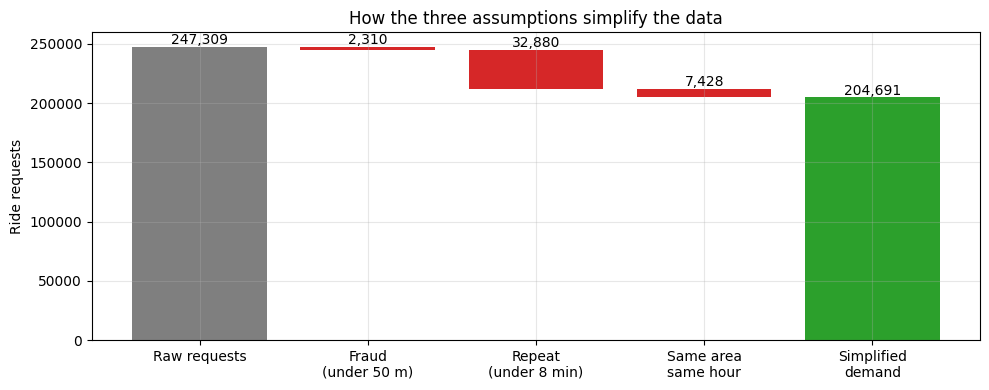

In [37]:
fig, ax = plt.subplots(figsize=(10, 4))
vals = [rule_log.iloc[0, 2]] + list(-rule_log.iloc[1:, 1].values) + [rule_log.iloc[-1, 2]]
labels = ["Raw requests", "Fraud\n(under 50 m)", "Repeat\n(under 8 min)", "Same area\nsame hour", "Simplified\ndemand"]
cum = rule_log.iloc[0, 2]; bottoms = [0]; heights = [cum]
for r in rule_log.iloc[1:].itertuples(): cum -= r[2]; bottoms.append(cum); heights.append(r[2])
bottoms.append(0); heights.append(rule_log.iloc[-1, 2])
ax.bar(labels, heights, bottom=bottoms, color=["tab:gray", "tab:red", "tab:red", "tab:red", "tab:green"])
for i, (b, h) in enumerate(zip(bottoms, heights)): ax.text(i, b + h + max(heights) * 0.01, f"{h:,}", ha="center")
ax.set(title="How the three assumptions simplify the data", ylabel="Ride requests"); plt.tight_layout(); plt.show()

## 1.4 Exploratory analysis: when and where is ride demand? (military hours)

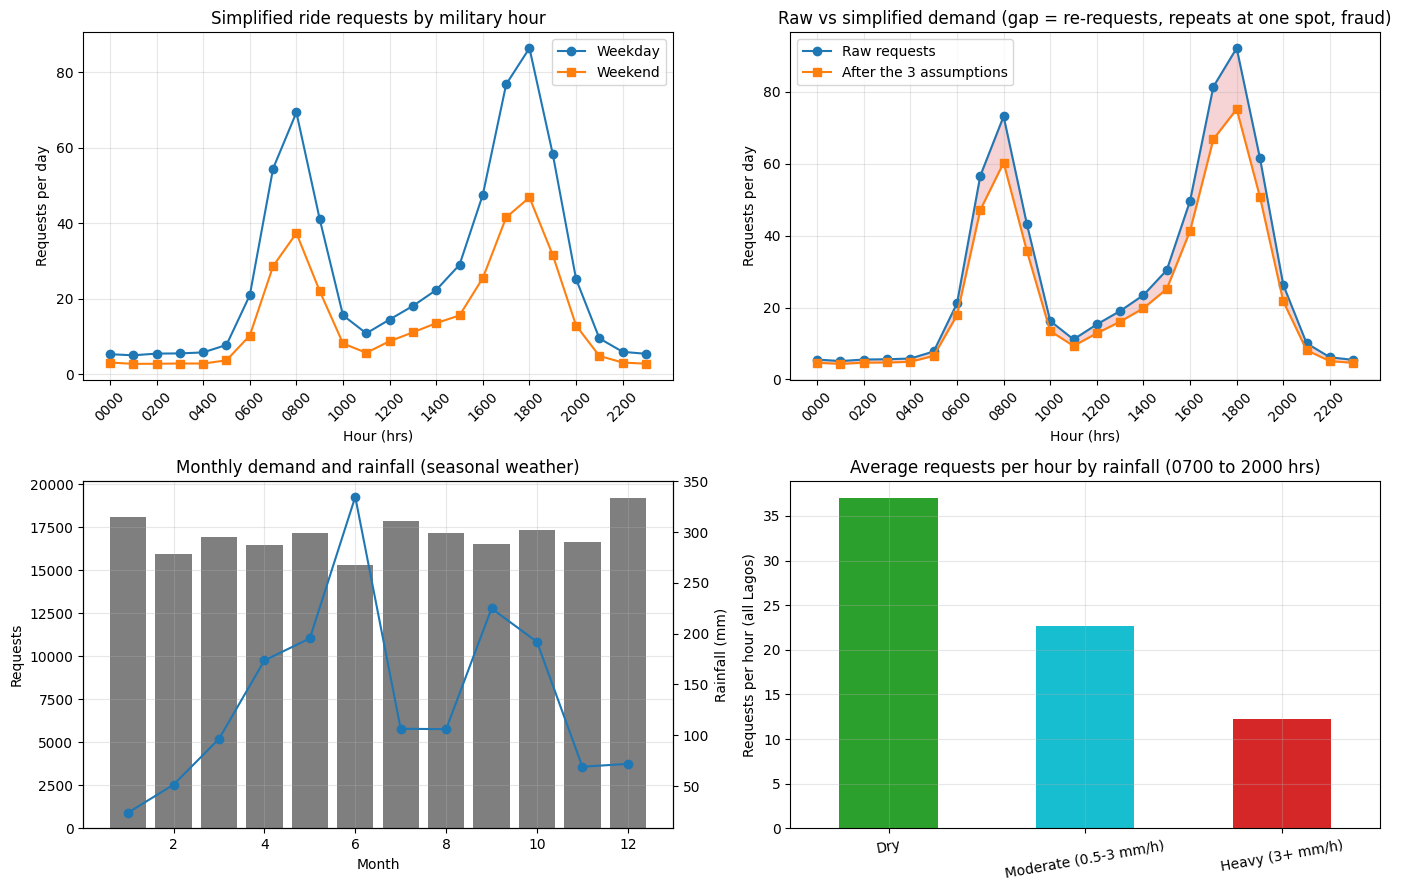

In [38]:
df["hour_24"] = df.request_time.dt.hour; df["dow"] = df.request_time.dt.dayofweek; df["month"] = df.request_time.dt.month
df["date"] = df.request_time.dt.normalize(); df["is_weekend"] = (df.dow >= 5).astype(int)
basic["hour_24"] = basic.request_time.dt.hour; basic["date"] = basic.request_time.dt.normalize()
n_wd = df[df.is_weekend == 0].date.nunique(); n_we = df[df.is_weekend == 1].date.nunique()
mil = lambda h: f"{h:02d}00"

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
wd = df[df.is_weekend == 0].groupby("hour_24").size() / n_wd; we = df[df.is_weekend == 1].groupby("hour_24").size() / n_we
ax[0, 0].plot(wd, marker="o", label="Weekday"); ax[0, 0].plot(we, marker="s", label="Weekend")
ax[0, 0].set_xticks(range(0, 24, 2)); ax[0, 0].set_xticklabels([mil(h) for h in range(0, 24, 2)], rotation=45)
ax[0, 0].set(title="Simplified ride requests by military hour", xlabel="Hour (hrs)", ylabel="Requests per day"); ax[0, 0].legend()

rawh = basic.groupby("hour_24").size() / basic.date.nunique(); clnh = df.groupby("hour_24").size() / df.date.nunique()
ax[0, 1].plot(rawh, marker="o", label="Raw requests"); ax[0, 1].plot(clnh, marker="s", label="After the 3 assumptions")
ax[0, 1].fill_between(rawh.index, clnh.reindex(rawh.index), rawh, alpha=0.2, color="tab:red")
ax[0, 1].set_xticks(range(0, 24, 2)); ax[0, 1].set_xticklabels([mil(h) for h in range(0, 24, 2)], rotation=45)
ax[0, 1].set(title="Raw vs simplified demand (gap = re-requests, repeats at one spot, fraud)", xlabel="Hour (hrs)", ylabel="Requests per day"); ax[0, 1].legend()

monthly = df.groupby("month").size(); wm = weather.assign(month=weather.hour_ts.dt.month).groupby("month").precip_mm.sum()
ax[1, 0].bar(monthly.index, monthly.values, color="tab:gray"); a2 = ax[1, 0].twinx(); a2.plot(wm.index, wm.values, color="tab:blue", marker="o"); a2.grid(False)
ax[1, 0].set(title="Monthly demand and rainfall (seasonal weather)", xlabel="Month", ylabel="Requests"); a2.set_ylabel("Rainfall (mm)")

hh = df.groupby("hour_ts").size().rename("req").reset_index().merge(weather[["hour_ts", "precip_mm"]], on="hour_ts")
hh = hh[hh.hour_ts.dt.hour.between(7, 20)]
hh["rain"] = pd.cut(hh.precip_mm, bins=[-0.01, 0.5, 3, 1000], labels=["Dry", "Moderate (0.5-3 mm/h)", "Heavy (3+ mm/h)"])
hh.groupby("rain").req.mean().plot.bar(ax=ax[1, 1], color=["tab:green", "tab:cyan", "tab:red"], rot=10)
ax[1, 1].set(title="Average requests per hour by rainfall (0700 to 2000 hrs)", ylabel="Requests per hour (all Lagos)", xlabel="")
plt.tight_layout(); plt.show()

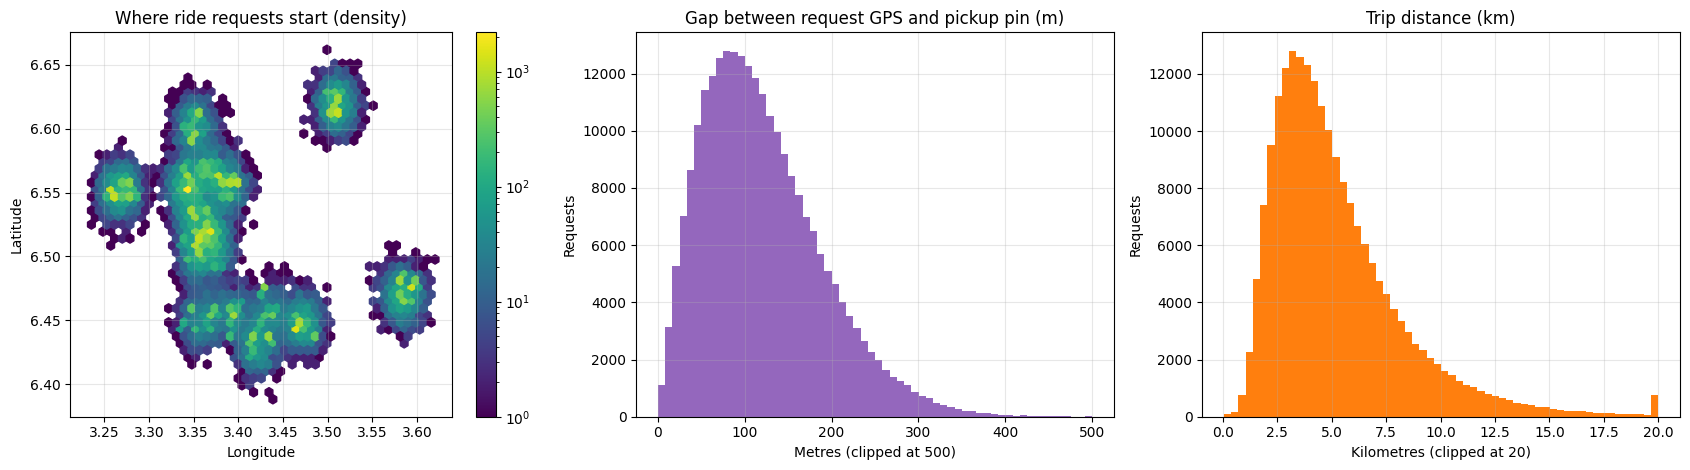

Busiest unique areas (about 110 m cells), a sign of motor parks, markets and junctions:


,area_lat,area_lng,requests
0,6.443,3.468,1053
1,6.444,3.468,1014
2,6.435,3.436,901
3,6.519,3.366,791
4,6.552,3.341,742
5,6.549,3.259,685
6,6.614,3.508,683
7,6.559,3.395,683


Median gap between request GPS and pickup pin: 110 m (poor street addressing makes pins drift from the user's real position)


In [39]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
s = df.sample(min(60_000, len(df)), random_state=SEED)
hb = ax[0].hexbin(s.request_longitude, s.request_latitude, gridsize=45, bins="log", cmap="viridis", mincnt=1)
ax[0].set(title="Where ride requests start (density)", xlabel="Longitude", ylabel="Latitude"); plt.colorbar(hb, ax=ax[0])
off = haversine_m(basic.request_latitude.values, basic.request_longitude.values, basic.pickup_lat.values, basic.pickup_lng.values)
ax[1].hist(np.clip(off, 0, 500), bins=60, color="tab:purple"); ax[1].set(title="Gap between request GPS and pickup pin (m)", xlabel="Metres (clipped at 500)", ylabel="Requests")
dist_km = haversine_m(df.pickup_lat.values, df.pickup_lng.values, df.drop_lat.values, df.drop_lng.values) / 1000
ax[2].hist(np.clip(dist_km, 0, 20), bins=60, color="tab:orange"); ax[2].set(title="Trip distance (km)", xlabel="Kilometres (clipped at 20)", ylabel="Requests")
plt.tight_layout(); plt.show()

spots = df.groupby(["area_lat", "area_lng"]).size().sort_values(ascending=False).head(8).rename("requests").reset_index()
print("Busiest unique areas (about 110 m cells), a sign of motor parks, markets and junctions:"); display(spots)
print(f"Median gap between request GPS and pickup pin: {np.median(off):.0f} m (poor street addressing makes pins drift from the user's real position)")

---
# PHASE 2: Data Clustering and Model Building

## 2.1 Choose the number of areas for K-means
Request locations (latitude and longitude, converted to kilometres) are grouped by **K-means** into **areas**. The **elbow method** and the **silhouette score** guide the number of areas (searched between 8 and 16, so that areas stay detailed enough to be useful for dispatch).

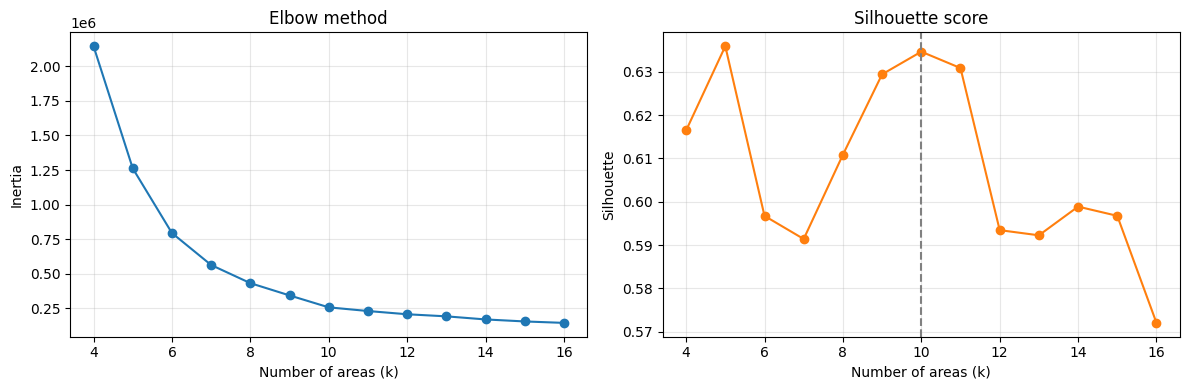

Selected k = 10 areas (best silhouette between 8 and 16)


In [40]:
lat0, lng0 = df.request_latitude.mean(), df.request_longitude.mean()
def to_km(lat, lng):
    return np.c_[(np.asarray(lng) - lng0) * np.cos(np.radians(lat0)) * 111.32, (np.asarray(lat) - lat0) * 110.57]

XY = to_km(df.request_latitude.values, df.request_longitude.values)
rng = np.random.default_rng(SEED)
fit_idx = rng.choice(len(XY), size=min(100_000, len(XY)), replace=False)
sil_idx = rng.choice(len(XY), size=min(10_000, len(XY)), replace=False)
rows = []
for k in range(4, 17):
    km_k = KMeans(n_clusters=k, n_init=5, random_state=SEED).fit(XY[fit_idx])
    rows.append((k, km_k.inertia_, silhouette_score(XY[sil_idx], km_k.predict(XY[sil_idx]))))
sel = pd.DataFrame(rows, columns=["k", "inertia", "silhouette"])
K = int(sel[sel.k.between(8, 16)].sort_values("silhouette", ascending=False).iloc[0].k)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(sel.k, sel.inertia, marker="o"); ax[0].set(title="Elbow method", xlabel="Number of areas (k)", ylabel="Inertia")
ax[1].plot(sel.k, sel.silhouette, marker="o", color="tab:orange"); ax[1].axvline(K, color="gray", linestyle="--")
ax[1].set(title="Silhouette score", xlabel="Number of areas (k)", ylabel="Silhouette")
plt.tight_layout(); plt.show()
print(f"Selected k = {K} areas (best silhouette between 8 and 16)")

## 2.2 Fit K-means and assign every request to an area

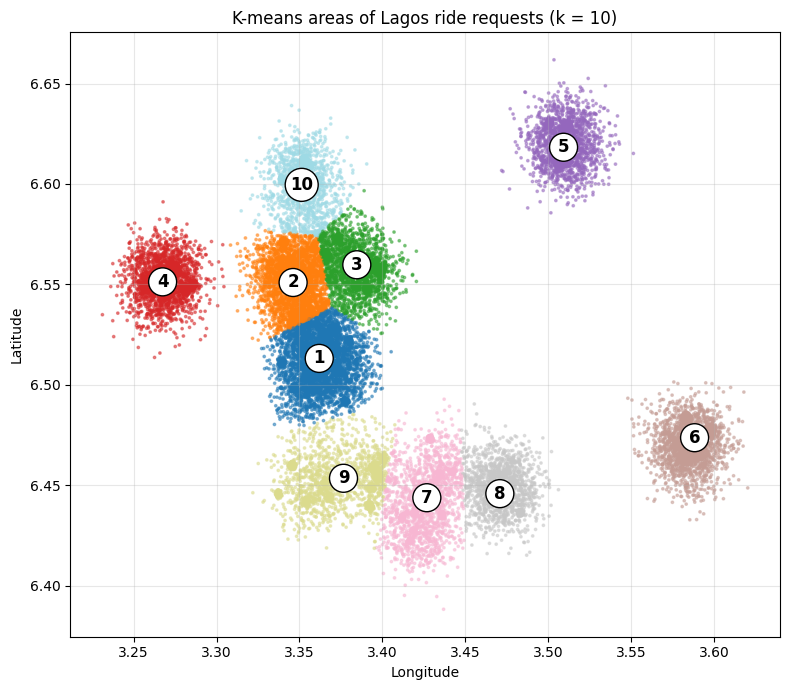

In [41]:
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(XY[fit_idx])
df["zone_raw"] = km.predict(XY)
order = df.zone_raw.value_counts().index.to_list()
remap = {old: new for new, old in enumerate(order)}
df["zone"] = df.zone_raw.map(remap)
centers_km = km.cluster_centers_[order]
c_lat = lat0 + centers_km[:, 1] / 110.57
c_lng = lng0 + centers_km[:, 0] / (np.cos(np.radians(lat0)) * 111.32)

def assign_zone(lat, lng):
    return pd.Series(km.predict(to_km(lat, lng))).map(remap).values

basic["zone"] = assign_zone(basic.request_latitude.values, basic.request_longitude.values)

plt.figure(figsize=(8, 7))
s = df.sample(min(50_000, len(df)), random_state=SEED)
plt.scatter(s.request_longitude, s.request_latitude, c=s.zone, cmap="tab20", s=3, alpha=0.5)
for i, (la, ln) in enumerate(zip(c_lat, c_lng)):
    plt.text(ln, la, str(i + 1), fontsize=12, fontweight="bold", ha="center", va="center", bbox=dict(boxstyle="circle", fc="white", ec="black"))
plt.title(f"K-means areas of Lagos ride requests (k = {K})"); plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.tight_layout(); plt.show()

## 2.3 Profile each area and group areas by their hourly demand pattern
Each area is described by its demand pattern and by the **re-request inflation** (raw requests divided by simplified demand). High inflation means many cancelled or abandoned pickups, a symptom of street-level friction: agbero levies, official and police stops, bad roads, flooding and unfindable addresses.

A second K-means run (k = 3) then groups the areas by their **24-hour demand profile**: the share of weekday demand and the share of weekend demand in each military hour (48 numbers per area). Areas with similar daily rhythms end up together, for example **weekday commuter hubs** (sharp peaks near 0800 and 1800 hrs, quiet weekends) versus **weekend and leisure-leaning areas** (afternoon demand that holds up on weekends).

In [42]:
raw_n = basic.groupby("zone").size(); cl_n = df.groupby("zone").size()
wd_d = df[df.is_weekend == 0].groupby("zone").size() / n_wd; we_d = df[df.is_weekend == 1].groupby("zone").size() / n_we
peak = df[df.is_weekend == 0].groupby(["zone", "hour_24"]).size().unstack(fill_value=0).idxmax(axis=1)
b2 = basic.assign(off=haversine_m(basic.request_latitude.values, basic.request_longitude.values, basic.pickup_lat.values, basic.pickup_lng.values),
                  trip=haversine_m(basic.pickup_lat.values, basic.pickup_lng.values, basic.drop_lat.values, basic.drop_lng.values) / 1000)
prof = pd.DataFrame({
    "simplified_requests": cl_n, "share_%": 100 * cl_n / cl_n.sum(), "raw_requests": raw_n,
    "inflation_x": raw_n / cl_n, "weekday_vs_weekend": wd_d / we_d, "weekday_peak_hrs": peak.map(mil),
    "pin_gap_m": b2.groupby("zone").off.median(), "trip_km": b2.groupby("zone").trip.median(),
})
# hourly demand profile of every area: share of its weekday demand and of its weekend demand in each military hour
wdp = df[df.is_weekend == 0].groupby(["zone", "hour_24"]).size().unstack(fill_value=0).reindex(columns=range(24), fill_value=0)
wep = df[df.is_weekend == 1].groupby(["zone", "hour_24"]).size().unstack(fill_value=0).reindex(columns=range(24), fill_value=0)
wdp, wep = wdp.div(wdp.sum(axis=1), axis=0), wep.div(wep.sum(axis=1), axis=0)
km_arch = KMeans(n_clusters=3, n_init=20, random_state=SEED).fit(np.hstack([wdp.values, wep.values]))
prof["cluster"] = km_arch.labels_
order_c = prof.groupby("cluster").weekday_vs_weekend.mean().sort_values(ascending=False).index.to_list()   # most weekday-heavy first
names = dict(zip(order_c, ["Weekday commuter hubs", "Mixed all-week areas", "Weekend and leisure leaning"]))
prof["archetype"] = prof.cluster.map(names)
cluster_of = prof.cluster.copy(); prof = prof.drop(columns="cluster")
prof.index = [f"Area {i + 1}" for i in prof.index]
display(prof.round(2))
print(prof.archetype.value_counts().to_string())

,simplified_requests,share_%,raw_requests,inflation_x,weekday_vs_weekend,weekday_peak_hrs,pin_gap_m,trip_km,archetype
Area 1,38539,18.83,46682,1.21,2.00,1800,112.87,4.45,Weekday commuter hubs
Area 2,27865,13.61,34659,1.24,2.09,1800,129.17,4.47,Weekday commuter hubs
Area 3,23263,11.36,27713,1.19,1.98,1800,108.90,4.49,Weekday commuter hubs
Area 4,19865,9.70,24846,1.25,1.52,1800,138.04,4.50,Mixed all-week areas
Area 5,18243,8.91,22533,1.24,1.48,1800,130.63,4.51,Mixed all-week areas
Area 6,18113,8.85,21962,1.21,1.39,1800,122.23,4.47,Mixed all-week areas
Area 7,16855,8.23,19136,1.14,2.43,1800,67.62,4.47,Mixed all-week areas
Area 8,15150,7.40,17584,1.16,1.08,1700,75.49,4.49,Weekend and leisure leaning
Area 9,14427,7.05,17602,1.22,3.33,1800,118.73,4.52,Weekday commuter hubs
Area 10,12371,6.04,14592,1.18,3.21,1800,91.60,4.48,Weekday commuter hubs


archetype
Weekday commuter hubs          5
Mixed all-week areas           4
Weekend and leisure leaning    1


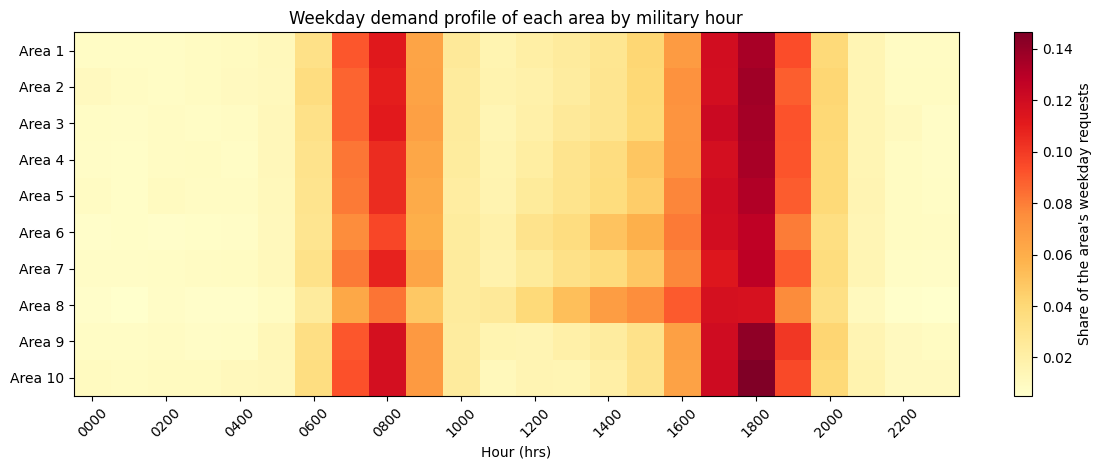

In [43]:
heat = df[df.is_weekend == 0].groupby(["zone", "hour_24"]).size().unstack(fill_value=0)
heat = heat.div(heat.sum(axis=1), axis=0)
plt.figure(figsize=(12, 4.8))
plt.imshow(heat.values, aspect="auto", cmap="YlOrRd")
plt.yticks(range(K), [f"Area {i + 1}" for i in range(K)]); plt.xticks(range(0, 24, 2), [mil(h) for h in range(0, 24, 2)], rotation=45)
plt.colorbar(label="Share of the area's weekday requests"); plt.title("Weekday demand profile of each area by military hour"); plt.xlabel("Hour (hrs)"); plt.grid(False)
plt.tight_layout(); plt.show()

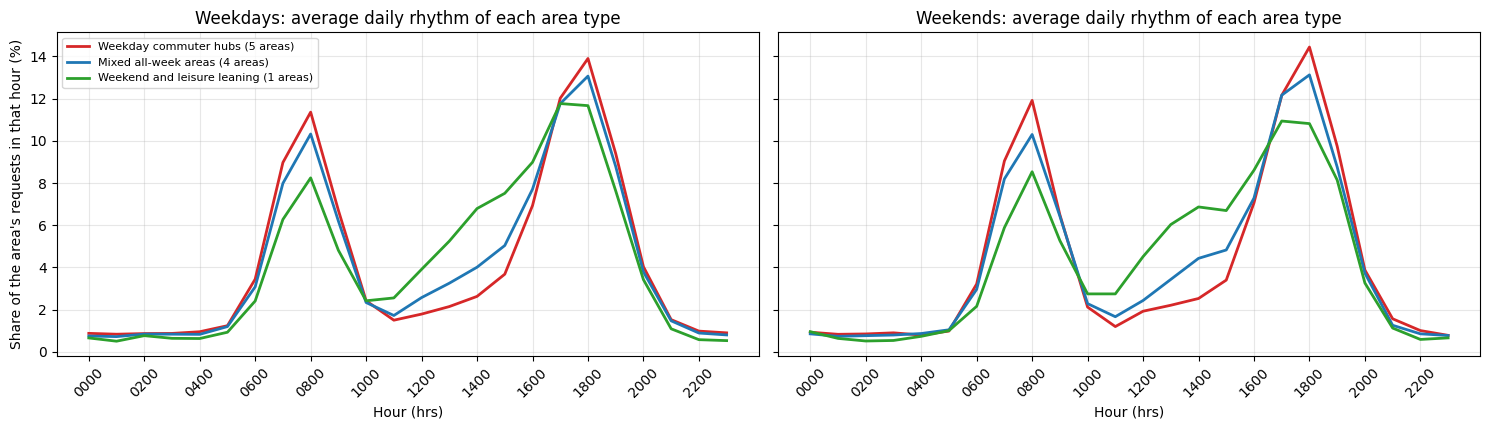

Weekday commuter hubs: Area 1, Area 2, Area 3, Area 9, Area 10
Mixed all-week areas: Area 4, Area 5, Area 6, Area 7
Weekend and leisure leaning: Area 8
How to use this: place bikes in commuter hubs before 0700 and 1600 hrs on weekdays; keep more bikes in leisure-leaning areas on weekend afternoons.


In [44]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4), sharey=True)
colors_a = {"Weekday commuter hubs": "tab:red", "Mixed all-week areas": "tab:blue", "Weekend and leisure leaning": "tab:green"}
for c, nm in names.items():
    members = cluster_of[cluster_of == c].index
    ax[0].plot(wdp.loc[members].mean() * 100, label=f"{nm} ({len(members)} areas)", color=colors_a[nm], lw=2)
    ax[1].plot(wep.loc[members].mean() * 100, label=nm, color=colors_a[nm], lw=2)
for a_, t_ in zip(ax, ("Weekdays", "Weekends")):
    a_.set_xticks(range(0, 24, 2)); a_.set_xticklabels([mil(h) for h in range(0, 24, 2)], rotation=45)
    a_.set(title=f"{t_}: average daily rhythm of each area type", xlabel="Hour (hrs)")
ax[0].set_ylabel("Share of the area's requests in that hour (%)"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
for nm in names.values():
    print(f"{nm}: " + ", ".join(prof[prof.archetype == nm].index))
print("How to use this: place bikes in commuter hubs before 0700 and 1600 hrs on weekdays; keep more bikes in leisure-leaning areas on weekend afternoons.")

## 2.4 Build the area-by-military-hour demand table and features
The target is the **number of simplified ride requests in an area during a clock hour**. An area is identified by its **latitude and longitude**, and the time by the **military hour** (0000 to 2300 hrs), the day, and the calendar. Every area-hour is included, including quiet ones. Real Lagos weather and demand history from one day and one week earlier are added.

In [45]:
all_hours = pd.date_range(df.hour_ts.min(), df.hour_ts.max(), freq="h")
counts = df.groupby(["zone", "hour_ts"]).size().rename("demand").reset_index()
grid = pd.MultiIndex.from_product([range(K), all_hours], names=["zone", "hour_ts"]).to_frame(index=False)
data = grid.merge(counts, on=["zone", "hour_ts"], how="left").fillna({"demand": 0})
data["demand"] = data.demand.astype(float)
raw_counts = basic.assign(hour_ts=basic.request_time.dt.floor("h")).groupby(["zone", "hour_ts"]).size().rename("raw_demand").reset_index()
data = data.merge(raw_counts, on=["zone", "hour_ts"], how="left").fillna({"raw_demand": 0})
demand_wide = data.pivot(index="hour_ts", columns="zone", values="demand")            # history, used by the forecast function

data["hour_24"] = data.hour_ts.dt.hour; data["dow"] = data.hour_ts.dt.dayofweek; data["month"] = data.hour_ts.dt.month
data["is_weekend"] = (data.dow >= 5).astype(int)
data["is_holiday"] = data.hour_ts.dt.normalize().isin(pd.to_datetime(HOLIDAYS)).astype(int)
data["is_payday"] = (data.hour_ts.dt.day >= 25).astype(int); data["is_december"] = (data.month == 12).astype(int)
data["hour_sin"] = np.sin(2 * np.pi * data.hour_24 / 24); data["hour_cos"] = np.cos(2 * np.pi * data.hour_24 / 24)
data["dow_sin"] = np.sin(2 * np.pi * data.dow / 7);        data["dow_cos"] = np.cos(2 * np.pi * data.dow / 7)
data = data.merge(weather[["hour_ts"] + WEATHER_COLS], on="hour_ts", how="left"); data[WEATHER_COLS] = data[WEATHER_COLS].ffill().bfill()
data["rain_moderate"] = ((data.precip_mm >= 0.5) & (data.precip_mm < 3)).astype(int); data["rain_heavy"] = (data.precip_mm >= 3).astype(int)
data = data.sort_values(["zone", "hour_ts"]).reset_index(drop=True)
data["rain_last_3h"] = data.groupby("zone").precip_mm.transform(lambda s: s.shift(1).rolling(3, min_periods=1).sum()).fillna(0)
g = data.groupby("zone")["demand"]
data["lag_24"] = g.shift(24); data["lag_168"] = g.shift(168); data["roll24_lag24"] = g.transform(lambda s: s.shift(24).rolling(24).mean())
data = data.dropna(subset=["lag_168", "roll24_lag24"]).sort_values(["hour_ts", "zone"]).reset_index(drop=True)

data["area_lat"] = data.zone.map(dict(enumerate(c_lat))); data["area_lng"] = data.zone.map(dict(enumerate(c_lng)))     # the area, by latitude and longitude
zone_dummies = pd.get_dummies(data.zone, prefix="area").astype(int); data = pd.concat([data, zone_dummies], axis=1)

days = np.sort(data.hour_ts.dt.normalize().unique()); cutoff = days[int(len(days) * 0.8)]
train, test = data[data.hour_ts < cutoff].copy(), data[data.hour_ts >= cutoff].copy()
zone_avg = train.groupby("zone").demand.mean(); train["area_avg_demand"] = train.zone.map(zone_avg); test["area_avg_demand"] = test.zone.map(zone_avg)

TIME_F = ["hour_24", "dow", "month", "is_weekend", "is_holiday", "is_payday", "is_december", "hour_sin", "hour_cos", "dow_sin", "dow_cos"]
LAG_F = ["lag_24", "lag_168", "roll24_lag24"]
WX_F = WEATHER_COLS + ["rain_moderate", "rain_heavy", "rain_last_3h"]
ZONE_F = ["area_lat", "area_lng", "area_avg_demand"] + list(zone_dummies.columns)
features = TIME_F + LAG_F + WX_F + ZONE_F
Xtr, ytr, Xte, yte = train[features], train.demand, test[features], test.demand
print(f"Area-hour rows: {len(data):,} | train: {len(train):,} (to {str(cutoff)[:10]}) | test: {len(test):,} | features: {len(features)}")
print(f"Average demand per area-hour: {data.demand.mean():.2f} requests | busiest area-hour: {data.demand.max():.0f} | raw inflation: {data.raw_demand.sum() / data.demand.sum():.2f}x")
data[["zone", "area_lat", "area_lng", "hour_ts", "hour_24", "demand", "raw_demand", "lag_24", "lag_168"]].head()

Area-hour rows: 85,920 | train: 68,640 (to 2025-10-21) | test: 17,280 | features: 34
Average demand per area-hour: 2.34 requests | busiest area-hour: 30 | raw inflation: 1.21x


,zone,area_lat,area_lng,hour_ts,hour_24,demand,raw_demand,lag_24,lag_168
0,0,6.513124,3.361919,2025-01-08,0,1.0,1.0,3.0,0.0
1,1,6.550922,3.346150,2025-01-08,0,2.0,3.0,0.0,0.0
2,2,6.559742,3.384579,2025-01-08,0,1.0,1.0,0.0,0.0
3,3,6.551235,3.267418,2025-01-08,0,1.0,1.0,1.0,2.0
4,4,6.618261,3.509316,2025-01-08,0,1.0,1.0,1.0,0.0


---
# PHASE 3: Evaluating Various Model Approaches

## 3.1 Train and compare forecasting models
Compared on the held-out **last 20% of the year**: a seasonal-naive baseline ("same area and hour last week"), Linear Regression, Random Forest, Gradient Boosting (Poisson loss, suited to counts) and XGBoost. Metrics: **MAE**, **RMSE**, **R²**, **WAPE** (total error as a % of total requests) and **accuracy within ±2 requests**.

In [46]:
def metrics(y, p):
    p = np.clip(np.asarray(p), 0, None)
    return {"MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** 0.5, "R2": r2_score(y, p),
            "WAPE_%": 100 * np.abs(y - p).sum() / max(y.sum(), 1), "Within_2_requests_%": 100 * (np.abs(y - p) <= 2).mean()}

results, preds, fitted = {}, {}, {}
preds["Seasonal naive (last week)"] = test.lag_168.values
results["Seasonal naive (last week)"] = metrics(yte, preds["Seasonal naive (last week)"])
candidates = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=120, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    "Gradient Boosting": HistGradientBoostingRegressor(loss="poisson", learning_rate=0.08, max_iter=300, random_state=SEED),
}
try:
    from xgboost import XGBRegressor
    candidates["XGBoost"] = XGBRegressor(objective="count:poisson", n_estimators=400, learning_rate=0.05, max_depth=6,
                                         subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1)
except Exception:
    print("XGBoost not installed: skipping it")
for name, model in candidates.items():
    model.fit(Xtr, ytr); preds[name] = model.predict(Xte); results[name] = metrics(yte, preds[name]); fitted[name] = model
    print("trained", name)

trained Linear Regression
trained Random Forest
trained Gradient Boosting
trained XGBoost


## 3.2 Tune the Gradient Boosting model
Randomized search with **time-series cross-validation** (training always precedes validation).

In [47]:
param_dist = {"learning_rate": [0.03, 0.05, 0.08, 0.1], "max_leaf_nodes": [15, 31, 63], "min_samples_leaf": [10, 20, 40],
              "l2_regularization": [0.0, 0.1, 1.0], "max_iter": [200, 300, 500]}
search = RandomizedSearchCV(HistGradientBoostingRegressor(loss="poisson", random_state=SEED), param_distributions=param_dist,
                            n_iter=8, cv=TimeSeriesSplit(n_splits=3), scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=-1)
search.fit(Xtr, ytr)
print("Best settings:", search.best_params_, f"| cross-validated MAE: {-search.best_score_:.3f}")
fitted["Gradient Boosting (tuned)"] = search.best_estimator_
preds["Gradient Boosting (tuned)"] = search.best_estimator_.predict(Xte)
results["Gradient Boosting (tuned)"] = metrics(yte, preds["Gradient Boosting (tuned)"])

Best settings: {'min_samples_leaf': 10, 'max_leaf_nodes': 15, 'max_iter': 500, 'learning_rate': 0.03, 'l2_regularization': 0.1} | cross-validated MAE: 1.096


## 3.3 Results: which model forecasts ride-request demand best?

,MAE,RMSE,R2,WAPE_%,Within_2_requests_%
Gradient Boosting (tuned),1.118,1.609,0.746,45.269,84.444
Gradient Boosting,1.119,1.614,0.744,45.289,84.288
XGBoost,1.120,1.614,0.744,45.349,84.277
Random Forest,1.151,1.659,0.730,46.587,83.420
Linear Regression,1.284,1.916,0.640,51.995,79.988
Seasonal naive (last week),1.510,2.279,0.490,61.148,80.625



BEST MODEL: Gradient Boosting (tuned) | RMSE 1.609 vs 2.279 for the naive baseline (29% lower) | R2 = 0.746


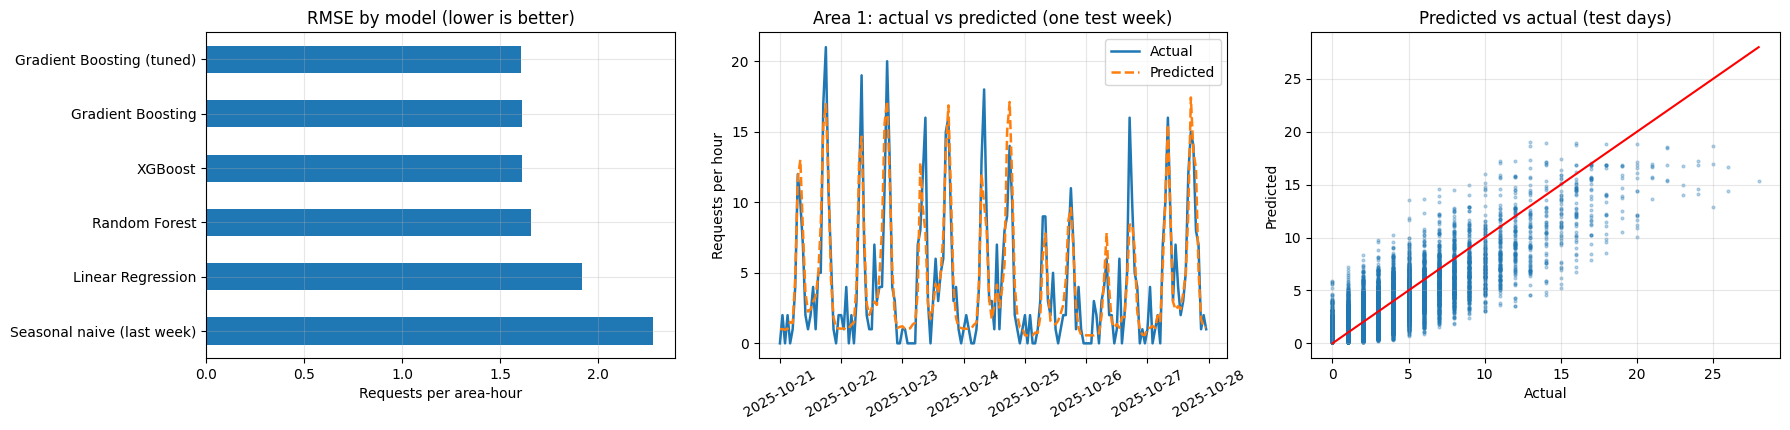

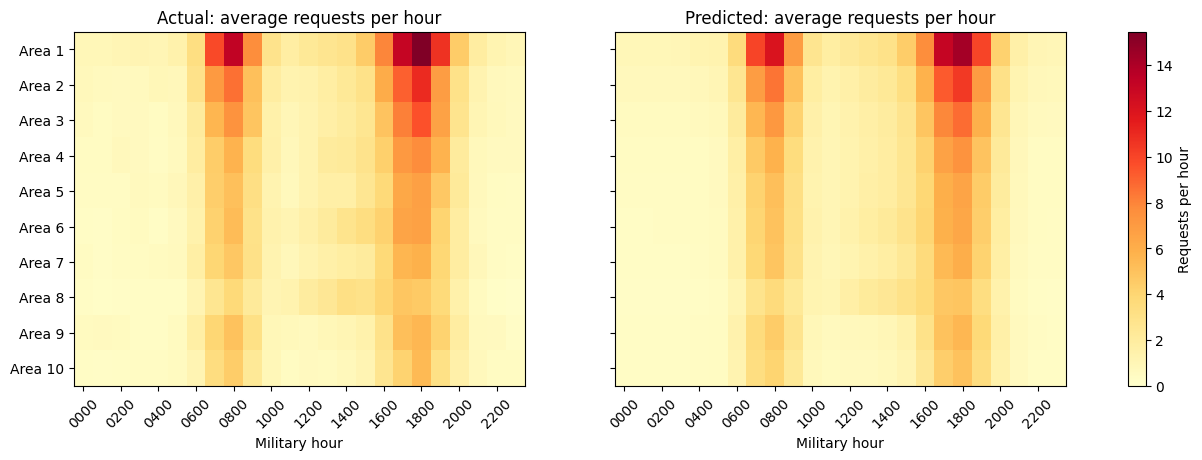

In [48]:
res = pd.DataFrame(results).T.sort_values("RMSE"); display(res.round(3))
best_name = [n for n in res.index if n in fitted][0]; best_model = fitted[best_name]
base = res.loc["Seasonal naive (last week)"]
print(f"\nBEST MODEL: {best_name} | RMSE {res.loc[best_name, 'RMSE']:.3f} vs {base.RMSE:.3f} for the naive baseline "
      f"({1 - res.loc[best_name, 'RMSE'] / base.RMSE:.0%} lower) | R2 = {res.loc[best_name, 'R2']:.3f}")

test = test.assign(pred=np.clip(preds[best_name], 0, None))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
res["RMSE"].sort_values(ascending=False).plot.barh(ax=ax[0], color="tab:blue"); ax[0].set(title="RMSE by model (lower is better)", xlabel="Requests per area-hour")
wk = test[test.zone == 0].iloc[: 24 * 7]
ax[1].plot(wk.hour_ts, wk.demand, label="Actual", lw=1.8); ax[1].plot(wk.hour_ts, wk.pred, "--", label="Predicted", lw=1.8)
ax[1].set(title="Area 1: actual vs predicted (one test week)", ylabel="Requests per hour"); ax[1].legend(); ax[1].tick_params(axis="x", rotation=30)
ax[2].scatter(test.demand, test.pred, s=4, alpha=0.3); lim = max(test.demand.max(), test.pred.max()); ax[2].plot([0, lim], [0, lim], color="red")
ax[2].set(title="Predicted vs actual (test days)", xlabel="Actual", ylabel="Predicted")
plt.tight_layout(); plt.show()

act = test.pivot_table(index="zone", columns="hour_24", values="demand", aggfunc="mean"); prd = test.pivot_table(index="zone", columns="hour_24", values="pred", aggfunc="mean")
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6), sharey=True)
for a, m, t in zip(ax, (act, prd), ("Actual", "Predicted")):
    im = a.imshow(m.values, aspect="auto", cmap="YlOrRd", vmin=0, vmax=max(act.values.max(), prd.values.max()))
    a.set_title(f"{t}: average requests per hour"); a.set_xlabel("Military hour"); a.set_xticks(range(0, 24, 2)); a.set_xticklabels([mil(h) for h in range(0, 24, 2)], rotation=45); a.grid(False)
ax[0].set_yticks(range(K)); ax[0].set_yticklabels([f"Area {i + 1}" for i in range(K)]); plt.colorbar(im, ax=ax, label="Requests per hour")
plt.show()

## 3.4 What drives demand? Does K-means help? Where are the errors?

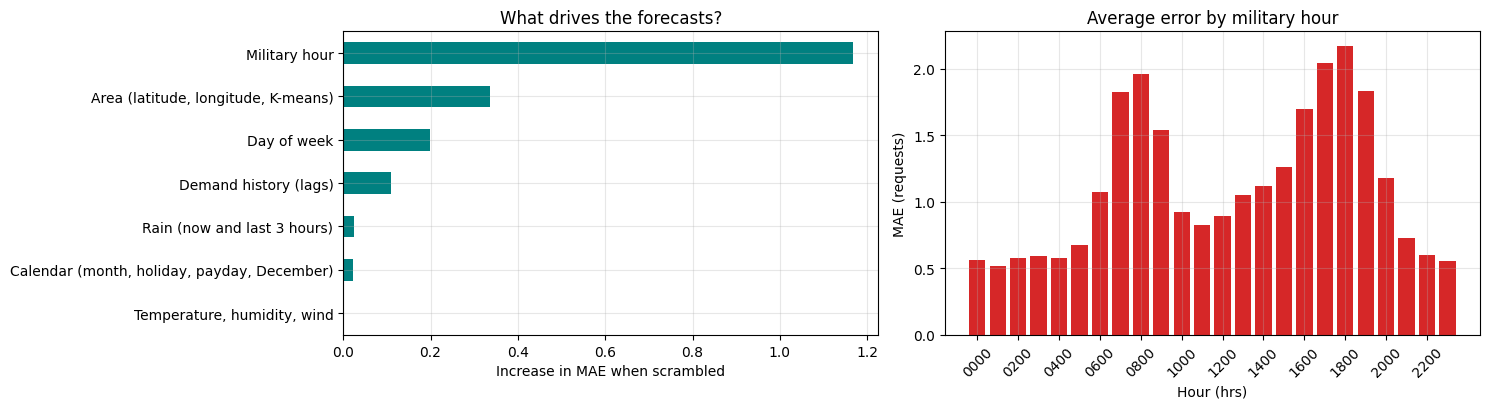

Same model without the area (K-means) features: RMSE 1.697 | with: 1.609 -> clustering changes RMSE by +5%


In [49]:
groups = {"Military hour": ["hour_24", "hour_sin", "hour_cos"], "Day of week": ["dow", "dow_sin", "dow_cos", "is_weekend"],
          "Calendar (month, holiday, payday, December)": ["month", "is_holiday", "is_payday", "is_december"],
          "Demand history (lags)": LAG_F, "Rain (now and last 3 hours)": ["precip_mm", "rain_moderate", "rain_heavy", "rain_last_3h"],
          "Temperature, humidity, wind": ["temp_c", "humidity", "wind_kmh"], "Area (latitude, longitude, K-means)": ZONE_F}
samp = test.sample(min(4000, len(test)), random_state=SEED); Xs, ys = samp[features], samp.demand
base_mae = mean_absolute_error(ys, np.clip(best_model.predict(Xs), 0, None)); rs = np.random.default_rng(SEED); imp = {}
for gname, cols in groups.items():
    inc = []
    for _ in range(3):
        Xp = Xs.copy(); Xp[cols] = Xs[cols].values[rs.permutation(len(Xp))]
        inc.append(mean_absolute_error(ys, np.clip(best_model.predict(Xp), 0, None)) - base_mae)
    imp[gname] = np.mean(inc)
imp = pd.Series(imp).sort_values()

err_h = test.assign(ae=(test.demand - test.pred).abs()).groupby("hour_24").ae.mean()
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
imp.plot.barh(ax=ax[0], color="teal"); ax[0].set(title="What drives the forecasts?", xlabel="Increase in MAE when scrambled")
ax[1].bar(err_h.index, err_h.values, color="tab:red"); ax[1].set(title="Average error by military hour", xlabel="Hour (hrs)", ylabel="MAE (requests)")
ax[1].set_xticks(range(0, 24, 2)); ax[1].set_xticklabels([mil(h) for h in range(0, 24, 2)], rotation=45)
plt.tight_layout(); plt.show()

no_zone = TIME_F + LAG_F + WX_F
m_nz = HistGradientBoostingRegressor(loss="poisson", random_state=SEED, **search.best_params_).fit(train[no_zone], ytr)
r_nz, r_full = metrics(yte, m_nz.predict(test[no_zone])), results["Gradient Boosting (tuned)"]
print(f"Same model without the area (K-means) features: RMSE {r_nz['RMSE']:.3f} | with: {r_full['RMSE']:.3f} -> clustering changes RMSE by {1 - r_full['RMSE'] / r_nz['RMSE']:+.0%}")

## 3.5 Predict the demand for any area at any military hour
forecast_area (latitude, longitude, time) finds the K-means area that contains the coordinates, builds the features for the requested clock hour (using the demand one day and one week earlier, and the weather), and returns the expected number of ride requests. For hours beyond the data you can pass the expected rainfall.

,Place,Latitude,Longitude,Military hour,Area,Predicted requests,Actual requests
0,Ikeja,6.6018,3.3515,0800 hrs,Area 10,5.7,5.0
1,Ikeja,6.6018,3.3515,1300 hrs,Area 10,0.5,0.0
2,Ikeja,6.6018,3.3515,1800 hrs,Area 10,6.9,7.0
3,Ikeja,6.6018,3.3515,2200 hrs,Area 10,0.6,2.0
4,Victoria Island,6.4281,3.4219,0800 hrs,Area 7,6.4,2.0
5,Victoria Island,6.4281,3.4219,1300 hrs,Area 7,0.9,1.0
6,Victoria Island,6.4281,3.4219,1800 hrs,Area 7,8.2,8.0
7,Victoria Island,6.4281,3.4219,2200 hrs,Area 7,0.5,0.0
8,Oshodi,6.5550,3.3430,0800 hrs,Area 2,10.4,7.0
9,Oshodi,6.5550,3.3430,1300 hrs,Area 2,1.4,3.0


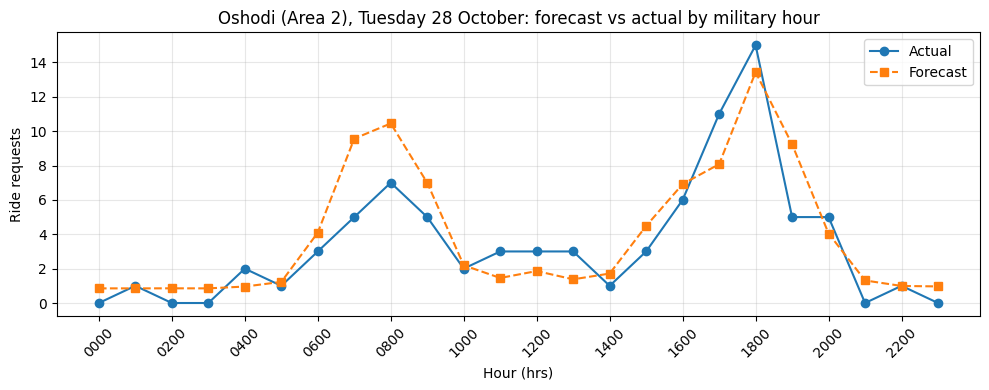

In [50]:
HIST_END = demand_wide.index.max()
def forecast_area(lat, lng, when, rain_mm=None, model=None):
    """Expected number of simplified ride requests in the area containing (lat, lng) during the clock hour starting at `when`."""
    model = model or best_model
    when = pd.Timestamp(when).floor("h")
    assert when <= HIST_END + pd.Timedelta(hours=24), "Time too far ahead: demand history one day earlier is needed"
    z = int(assign_zone(np.array([lat]), np.array([lng]))[0])
    lag24 = demand_wide.loc[when - pd.Timedelta(hours=24), z]; lag168 = demand_wide.loc[when - pd.Timedelta(hours=168), z]
    r24 = demand_wide.loc[when - pd.Timedelta(hours=47): when - pd.Timedelta(hours=24), z].mean()
    w = weather.set_index("hour_ts")
    if when in w.index and rain_mm is None:
        wx = w.loc[when]; last3 = w.loc[when - pd.Timedelta(hours=3): when - pd.Timedelta(hours=1), "precip_mm"].sum()
    else:
        rain_mm = 0.0 if rain_mm is None else rain_mm
        wx = pd.Series({"temp_c": w.temp_c.median(), "humidity": w.humidity.median(), "precip_mm": rain_mm, "wind_kmh": w.wind_kmh.median()}); last3 = rain_mm
    if rain_mm is not None and when in w.index: wx = wx.copy(); wx["precip_mm"] = rain_mm; last3 = rain_mm
    row = {"hour_24": when.hour, "dow": when.dayofweek, "month": when.month, "is_weekend": int(when.dayofweek >= 5),
           "is_holiday": int(when.normalize() in set(pd.to_datetime(HOLIDAYS))), "is_payday": int(when.day >= 25), "is_december": int(when.month == 12),
           "hour_sin": np.sin(2 * np.pi * when.hour / 24), "hour_cos": np.cos(2 * np.pi * when.hour / 24),
           "dow_sin": np.sin(2 * np.pi * when.dayofweek / 7), "dow_cos": np.cos(2 * np.pi * when.dayofweek / 7),
           "lag_24": lag24, "lag_168": lag168, "roll24_lag24": r24, "temp_c": wx.temp_c, "humidity": wx.humidity, "precip_mm": wx.precip_mm,
           "wind_kmh": wx.wind_kmh, "rain_moderate": int(0.5 <= wx.precip_mm < 3), "rain_heavy": int(wx.precip_mm >= 3), "rain_last_3h": last3,
           "area_lat": c_lat[z], "area_lng": c_lng[z], "area_avg_demand": zone_avg[z]}
    for c in zone_dummies.columns: row[c] = int(c == f"area_{z}")
    return float(np.clip(model.predict(pd.DataFrame([row])[features])[0], 0, None)), z

# examples: three Lagos locations on a weekday of the test period at 0800 and 1800 hrs
day = pd.Timestamp(cutoff) + pd.Timedelta(days=(7 - pd.Timestamp(cutoff).dayofweek) % 7 + 1)      # a Tuesday
places = {"Ikeja": (6.6018, 3.3515), "Victoria Island": (6.4281, 3.4219), "Oshodi": (6.5550, 3.3430)}
rows = []
for name, (la, lo) in places.items():
    for hh in (8, 13, 18, 22):
        t0 = day + pd.Timedelta(hours=hh); p, z = forecast_area(la, lo, t0)
        a = demand_wide.loc[t0, z]
        rows.append({"Place": name, "Latitude": la, "Longitude": lo, "Military hour": f"{hh:02d}00 hrs", "Area": f"Area {z + 1}",
                     "Predicted requests": round(p, 1), "Actual requests": a})
display(pd.DataFrame(rows))

# a full 24-hour forecast for one area
z_demo = int(assign_zone(np.array([6.5550]), np.array([3.3430]))[0])
fc = [forecast_area(6.5550, 3.3430, day + pd.Timedelta(hours=h))[0] for h in range(24)]
ac = [demand_wide.loc[day + pd.Timedelta(hours=h), z_demo] for h in range(24)]
plt.figure(figsize=(10, 4)); plt.plot(range(24), ac, marker="o", label="Actual"); plt.plot(range(24), fc, marker="s", linestyle="--", label="Forecast")
plt.xticks(range(0, 24, 2), [mil(h) for h in range(0, 24, 2)], rotation=45)
plt.title(f"Oshodi (Area {z_demo + 1}), {day:%A %d %B}: forecast vs actual by military hour"); plt.xlabel("Hour (hrs)"); plt.ylabel("Ride requests"); plt.legend()
plt.tight_layout(); plt.show()

## 3.6 Why Lagos is different: factors and sources

| Factor in Lagos / Nigeria | What reporting says | How it appears here |
|---|---|---|
| **Agberos (ticket touts)** | Motorcyclists were reported paying about ₦400 to ₦800 a day to agberos ([Economy Post / ICIR](https://economypost.ng/featured/money-for-the-boys-how-agberos-pocket-billions-of-lagos-transport-revenue/2025/12/15/)); researchers describe extortion and, at times, complicity among agberos, drivers and police ([Fourchard](https://kolaking.substack.com/p/they-eat-our-sweat-new-book-exposes)) | Higher chance of cancelled pickups and **re-requests** in agbero-heavy districts (Section 0.4) |
| **Local-government officials, LASTMA and police** | Lagos State has acted against council traffic officials accused of illegal arrests and extortion ([The Guardian Nigeria](https://www.pressreader.com/nigeria/the-guardian-nigeria/20180528/281698320419954)); a dispatch rider described harassment by police, agberos and LASTMA ([Gistlover](https://www.gistlover.com/i-have-no-peace-of-mind-dispatch-rider-cries-out-over-alleged-harassment-by-police-agberos-and-lastma/)); Lagos police opened an investigation in Oct 2026 into an alleged ₦20,000 extortion of a dispatch rider (not independently verified) ([Crime Focus News](https://crimefocusnews.com/lagos-police-probe-alleged-%E2%82%A620000-extortion-of-dispatch-rider/)) | Same: riders who are stopped or avoid hotspots cancel, and users ask again |
| **Motorbike restrictions** | A 2012 Lagos law banned motorbikes on major roads and in wealthy neighbourhoods ([Fourchard](https://kolaking.substack.com/p/they-eat-our-sweat-new-book-exposes)); bike-hailing was restricted in 2020 ([Quartz](https://qz.com/africa/1792504/lagos-bans-okada-oride-gokada-keke-tricycles)) | Low bike-ride demand weights in central districts |
| **Poor street naming and house numbering** | NIPOST's Postmaster General said more than ₦50 billion is lost each year to failed or inaccurate deliveries because of weak addressing ([The Condia](https://thecondia.com/maiaddy-location-identity-nigeria/)); platforms rely on landmarks and phone calls ([Techpoint Africa](https://techpoint.africa/2020/08/20/challenges-ecommerce-logistics-nigeria/)) | Larger gap between request GPS and pickup pin; more re-requests |
| **Bad roads, potholes, floods, diversions** | Bad roads, potholes, floods and sudden diversions force reroutes and make times unpredictable ([The Guardian Nigeria](https://guardian.ng/?p=2811595)); potholes cause crashes and repair costs ([TechCabal](https://techcabal.com/?p=117959)) | Real Lagos rainfall; fewer bike requests in rain; more re-requests in bad-road, flood-prone areas |
| **Market shifts** | Uber ended Nigerian ride-hailing on 2 Sept 2026 ([Connecting Africa](https://www.connectingafrica.com/social-technology/uber-drives-away-from-nigeria-and-uganda)); Bolt Food closed in Dec 2023 ([TechCabal](https://techcabal.com/2023/11/09/bolt-food-pulls-the-plug-on-nigeria-operations/)) | Operators have less outside capital, so accurate forecasting matters more |

The sources show these problems *exist*. The probabilities and sizes in the simulator are *assumptions*; I found no study that measures them for ride requests.

## 3.7 What-if scenarios for Lagos
**(a) Using the trained model** on the test days: predicted demand if every afternoon had a storm, every day were in a payday week, or it were December. **(b) Using the simulator as ground truth:** the same storm scenario is simulated, the three assumptions applied, and the change in simplified demand compared with the model's prediction (a check that the model has learnt the right sensitivity). **(c) Friction scenarios** (simulator): how agbero, official and police stops, worse roads and worse addresses inflate **raw** requests with re-requests while **simplified** demand barely changes.

All effects follow the assumptions in Section 0.2; they show direction and rough size, not real Lagos measurements.

In [51]:
STORM = [14, 15, 16, 17, 18]
tdays = test.hour_ts.dt.normalize().nunique()
def model_scenario(name, **chg):
    X = test[features].copy()
    if "storm" in chg:
        m = X.hour_24.isin(STORM); X.loc[m, "precip_mm"] = 4.0; X.loc[m, "rain_heavy"] = 1; X.loc[m, "rain_moderate"] = 0
        tmp = test[["zone", "hour_ts"]].copy(); tmp["p"] = X.precip_mm.values
        X["rain_last_3h"] = tmp.sort_values(["zone", "hour_ts"]).groupby("zone").p.transform(lambda s: s.shift(1).rolling(3, min_periods=1).sum()).fillna(0).reindex(tmp.index).values
    if "payday" in chg: X["is_payday"] = 1
    if "december" in chg: X["is_december"] = 1; X["month"] = 12
    p = np.clip(best_model.predict(X), 0, None)
    t = test[["hour_24"]].assign(p=p)
    return {"Scenario": name, "Requests per day": p.sum() / tdays, "Morning peak 0700-0959 hrs": t[t.hour_24.between(7, 9)].p.sum() / tdays,
            "Afternoon 1400-1859 hrs": t[t.hour_24.between(14, 18)].p.sum() / tdays, "Evening peak 1600-1959 hrs": t[t.hour_24.between(16, 19)].p.sum() / tdays}

ms = pd.DataFrame([model_scenario("Baseline (as forecast)"), model_scenario("Storms every afternoon (1400-1859 hrs)", storm=1),
                   model_scenario("Payday week (25th to month end)", payday=1), model_scenario("December festive season", december=1),
                   model_scenario("Storms and payday week", storm=1, payday=1)]).set_index("Scenario")
b0 = ms.iloc[0]
for c in list(ms.columns): ms[c + " (change %)"] = 100 * (ms[c] / b0[c] - 1)
print("(a) MODEL-PREDICTED demand under scenarios"); display(ms.round(1))
print("Note: the training data ends in October, so the model has never seen December and shows about 0% for the December scenario. "
      "A model cannot learn a season it has not seen, which is why a real pilot should collect at least a full year (ideally two) of data.")

# (b) simulator check of the storm effect over the same test days
def sim_demand(**kw):
    s = simulate_requests(weather, dirty=False, **kw); s["request_time"] = pd.to_datetime(s.request_time)
    cleaned, _ = apply_rules(s)
    cleaned = cleaned[cleaned.request_time >= cutoff]
    h = cleaned.request_time.dt.hour
    return {"per_day": len(cleaned) / tdays, "afternoon": cleaned[h.between(14, 18)].shape[0] / tdays}, s
sb, sim_base = sim_demand(); ss, _ = sim_demand(storm_hours=STORM)
print(f"\n(b) STORM EFFECT ON AFTERNOON DEMAND (1400-1859 hrs): model predicts {ms.iloc[1]['Afternoon 1400-1859 hrs (change %)']:+.1f}% | simulator ground truth {100 * (ss['afternoon'] / sb['afternoon'] - 1):+.1f}%")

(a) MODEL-PREDICTED demand under scenarios


,Requests per day,Morning peak 0700-0959 hrs,Afternoon 1400-1859 hrs,Evening peak 1600-1959 hrs,Requests per day (change %),Morning peak 0700-0959 hrs (change %),Afternoon 1400-1859 hrs (change %),Evening peak 1600-1959 hrs (change %)
Scenario,,,,,,,,
Baseline (as forecast),572.7,145.7,232.0,237.6,0.0,0.0,0.0,0.0
Storms every afternoon (1400-1859 hrs),456.6,145.7,115.6,143.2,-20.3,0.0,-50.2,-39.7
Payday week (25th to month end),608.9,154.4,247.1,254.2,6.3,5.9,6.5,7.0
December festive season,572.7,145.7,232.0,237.6,0.0,0.0,0.0,0.0
Storms and payday week,487.9,154.4,125.8,156.4,-14.8,6.0,-45.8,-34.2


Note: the training data ends in October, so the model has never seen December and shows about 0% for the December scenario. A model cannot learn a season it has not seen, which is why a real pilot should collect at least a full year (ideally two) of data.

(b) STORM EFFECT ON AFTERNOON DEMAND (1400-1859 hrs): model predicts -50.2% | simulator ground truth -51.4%


,Raw requests per day,Simplified demand per day,Raw / simplified (x),Removed as re-requests (%)
Scenario,,,,
1. Baseline,685.07,566.06,1.21,13.41
2. Storms every afternoon,549.58,448.35,1.23,14.78
"3. Agbero, official and police stops x2",726.12,572.88,1.27,16.83
4. Worse roads (-0.15) and addresses (-0.10),698.37,570.40,1.22,14.56
5. Everything worse at once,592.73,456.94,1.30,19.13
6. Better roads (+0.10) and addresses (+0.15),672.48,560.05,1.20,12.29


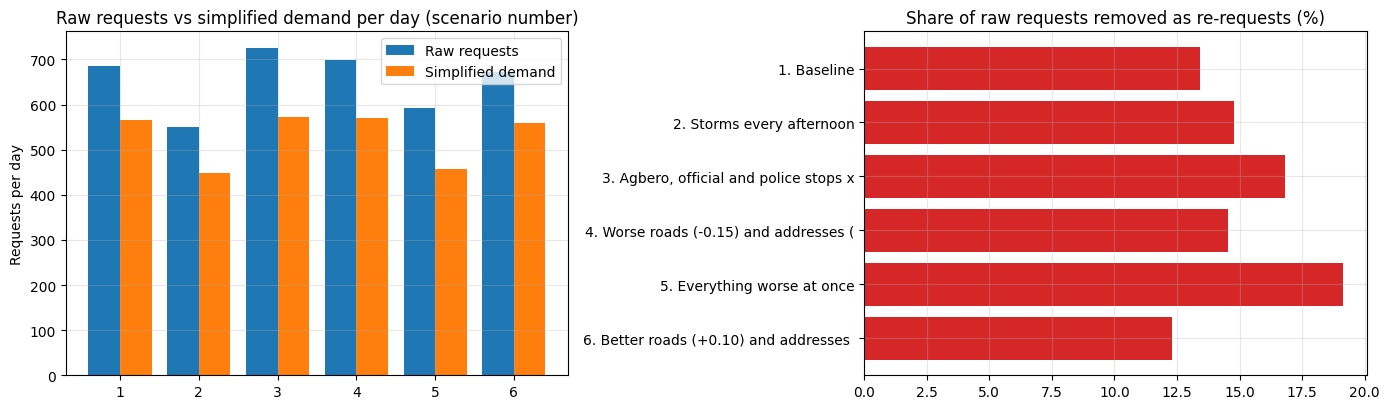

Reading: street-level friction mainly inflates RAW request counts (users asking again). Counting raw requests would send riders to phantom demand; the eight-minute rule keeps the forecast target honest.


In [52]:
FRICTION = {
    "1. Baseline": dict(),
    "2. Storms every afternoon": dict(storm_hours=STORM),
    "3. Agbero, official and police stops x2": dict(agbero_mult=2, lga_mult=2, police_mult=2),
    "4. Worse roads (-0.15) and addresses (-0.10)": dict(road_boost=-0.15, addr_boost=-0.10),
    "5. Everything worse at once": dict(storm_hours=STORM, agbero_mult=2, lga_mult=2, police_mult=2, road_boost=-0.15, addr_boost=-0.10),
    "6. Better roads (+0.10) and addresses (+0.15)": dict(road_boost=0.10, addr_boost=0.15),
}
rows = []
for name, kw in FRICTION.items():
    s = simulate_requests(weather, dirty=False, **kw); s["request_time"] = pd.to_datetime(s.request_time)
    cleaned, rl = apply_rules(s); nd = s.request_time.dt.normalize().nunique()
    rows.append({"Scenario": name, "Raw requests per day": len(s) / nd, "Simplified demand per day": len(cleaned) / nd,
                 "Raw / simplified (x)": len(s) / len(cleaned), "Removed as re-requests (%)": 100 * rl.iloc[2, 1] / len(s)})
fr = pd.DataFrame(rows).set_index("Scenario"); display(fr.round(2))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(len(fr)); w = 0.4
ax[0].bar(x - w / 2, fr["Raw requests per day"], w, label="Raw requests"); ax[0].bar(x + w / 2, fr["Simplified demand per day"], w, label="Simplified demand")
ax[0].set_xticks(x); ax[0].set_xticklabels([n.split(".")[0] for n in fr.index]); ax[0].set(title="Raw requests vs simplified demand per day (scenario number)", ylabel="Requests per day"); ax[0].legend()
ax[1].barh([n[:38] for n in fr.index][::-1], fr["Removed as re-requests (%)"].values[::-1], color="tab:red"); ax[1].set(title="Share of raw requests removed as re-requests (%)")
plt.tight_layout(); plt.show()
print("Reading: street-level friction mainly inflates RAW request counts (users asking again). Counting raw requests would send riders to phantom demand; the eight-minute rule keeps the forecast target honest.")

## 3.8 Fleet management: use the forecast to keep enough bikes in every area
The forecast is only useful if it changes where bikes are. This section converts forecasts into **bikes needed** and tests three ways of spreading a limited fleet across areas, hour by hour, on the unseen test days:

1. **Equal split:** the same number of bikes in every area.
2. **Static plan:** bikes follow each area's *average* demand for that military hour, learned from the training period.
3. **Forecast plan:** bikes follow the **model's forecast** for each area and hour.

*Bikes needed in an area = requests in the hour x ride time in hours* (Little's law). Ride time = trip distance at an average speed plus the pickup wait. Both numbers are ASSUMED and editable.

,Fleet size,Share of recommended fleet,Equal split: unmet (%),Static plan: unmet (%),Forecast plan: unmet (%)
0,17,50%,22.9,20.4,20.2
1,20,60%,17.2,14.3,14.1
2,23,70%,12.9,9.8,9.6
3,27,80%,9.7,6.4,6.4
4,30,90%,7.3,4.1,4.1
5,34,100%,5.6,2.5,2.5
6,40,120%,3.2,0.9,0.9


,Segment (fleet = 80% of recommended),Equal split: unmet (%),Static plan: unmet (%),Forecast plan: unmet (%)
0,Weekdays,11.2,7.4,7.4
1,Weekends,2.3,1.8,1.5
2,Dry hours,9.9,6.7,6.6
3,Rainy hours,5.5,2.2,2.0


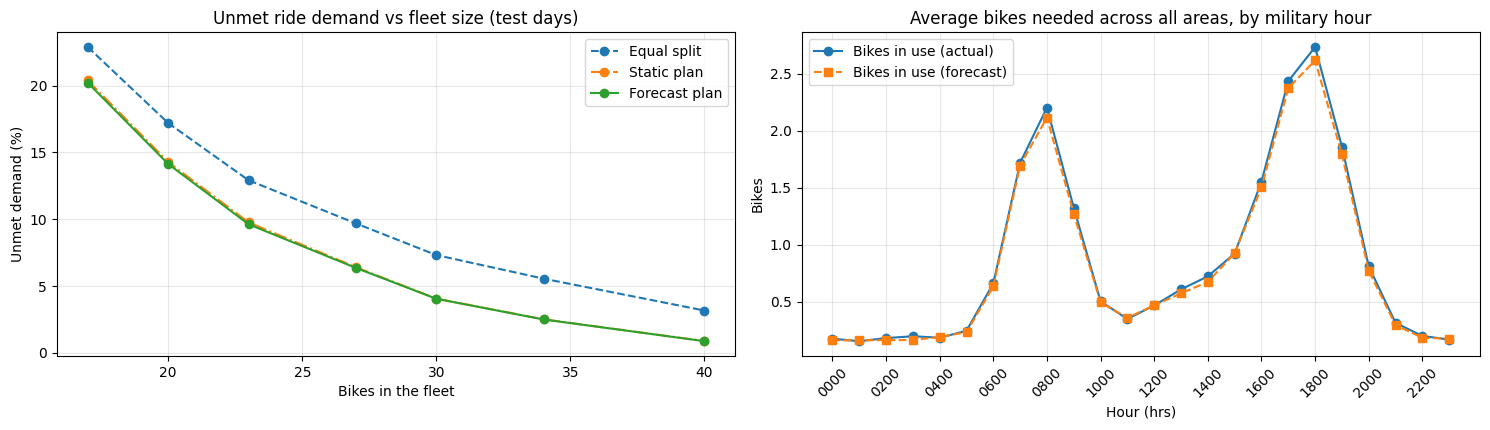

Bikes to have in place by 0700 hrs (forecast need + 20% buffer):


,Area 1,Area 2,Area 3,Area 4,Area 5,Area 6,Area 7,Area 8,Area 9,Area 10
need_pred,3.5,2.4,1.9,1.6,1.5,1.4,1.3,1.0,1.2,1.2
bikes_to_place,5.0,3.0,3.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0


Recommended fleet (covers 95% of hours with a 20% buffer): 34 bikes
With 80% of that fleet, unmet demand is 9.7% (equal split), 6.4% (static plan) and 6.4% (forecast plan)


In [53]:
SPEED_KMH = 18          # ASSUMED average bike speed in Lagos traffic (km/h)
PICKUP_MIN = 6          # ASSUMED average time for a bike to reach the customer (minutes)
BUFFER = 0.20           # ASSUMED spare bikes for breakdowns, charging and rain (20%)

trip_km_zone = prof["trip_km"].values                                   # median trip length per area (from the data)
ride_h = trip_km_zone / SPEED_KMH + PICKUP_MIN / 60                       # hours a bike is busy per request
t8 = test[["zone", "hour_ts", "hour_24", "demand", "pred"]].copy()
t8["ride_h"] = t8.zone.map(dict(enumerate(ride_h)))
t8["need_actual"] = t8.demand * t8.ride_h                                # bikes actually in use
t8["need_pred"] = t8.pred * t8.ride_h                                    # bikes the forecast says will be in use
avg_need = (train.assign(ride_h=train.zone.map(dict(enumerate(ride_h)))).assign(n=lambda d: d.demand * d.ride_h)
            .groupby(["zone", "hour_24"]).n.mean())                      # static plan: historical average by area and hour
t8["need_static"] = [avg_need.get((z, h), 0.0) for z, h in zip(t8.zone, t8.hour_24)]

city_need = t8.groupby("hour_ts").need_actual.sum()
FLEET_100 = int(np.ceil(city_need.quantile(0.95) * (1 + BUFFER)))        # fleet that covers 95% of city-wide hours with a 20% buffer

def serve(strategy_col, fleet):
    out = []
    for ts, g in t8.groupby("hour_ts"):
        if strategy_col == "equal": alloc = np.full(len(g), fleet / K)
        else:
            w = g[strategy_col].values + 1e-9; alloc = fleet * w / w.sum()
        out.append((np.minimum(g.need_actual.values, alloc).sum(), g.need_actual.sum()))
    served, need = np.array(out).sum(axis=0)
    return 100 * (1 - served / need)                                      # unmet demand (%)

fracs = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.2]
rows = [{"Fleet size": int(FLEET_100 * f), "Share of recommended fleet": f"{f:.0%}",
         "Equal split: unmet (%)": serve("equal", FLEET_100 * f), "Static plan: unmet (%)": serve("need_static", FLEET_100 * f),
         "Forecast plan: unmet (%)": serve("need_pred", FLEET_100 * f)} for f in fracs]
fleet_tbl = pd.DataFrame(rows); display(fleet_tbl.round(1))

# where does the forecast beat the static plan? weekdays vs weekends, dry vs rainy hours (fleet at 80% of recommended)
rainy = set(weather.hour_ts[weather.precip_mm >= 0.5])
t8_all = t8.copy()
def serve_subset(mask_fn, strat, fleet):
    global t8
    t8 = t8_all[mask_fn(t8_all)]
    try: return serve(strat, fleet)
    finally: t8 = t8_all
segs = {"Weekdays": lambda d: d.hour_ts.dt.dayofweek < 5, "Weekends": lambda d: d.hour_ts.dt.dayofweek >= 5,
        "Dry hours": lambda d: ~d.hour_ts.isin(rainy), "Rainy hours": lambda d: d.hour_ts.isin(rainy)}
seg_rows = [{"Segment (fleet = 80% of recommended)": nm, "Equal split: unmet (%)": serve_subset(fn, "equal", FLEET_100 * 0.8),
             "Static plan: unmet (%)": serve_subset(fn, "need_static", FLEET_100 * 0.8), "Forecast plan: unmet (%)": serve_subset(fn, "need_pred", FLEET_100 * 0.8)}
            for nm, fn in segs.items()]
display(pd.DataFrame(seg_rows).round(1))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
for c, st in [("Equal split: unmet (%)", "--"), ("Static plan: unmet (%)", "-."), ("Forecast plan: unmet (%)", "-")]:
    ax[0].plot(fleet_tbl["Fleet size"], fleet_tbl[c], st, marker="o", label=c.replace(": unmet (%)", ""))
ax[0].set(title="Unmet ride demand vs fleet size (test days)", xlabel="Bikes in the fleet", ylabel="Unmet demand (%)"); ax[0].legend()
hourly_need = t8.groupby("hour_24")[["need_actual", "need_pred"]].mean() * 1.0
ax[1].plot(hourly_need.index, hourly_need.need_actual, marker="o", label="Bikes in use (actual)"); ax[1].plot(hourly_need.index, hourly_need.need_pred, "--", marker="s", label="Bikes in use (forecast)")
ax[1].set_xticks(range(0, 24, 2)); ax[1].set_xticklabels([mil(h) for h in range(0, 24, 2)], rotation=45)
ax[1].set(title="Average bikes needed across all areas, by military hour", xlabel="Hour (hrs)", ylabel="Bikes"); ax[1].legend()
plt.tight_layout(); plt.show()

# morning plan: where should the fleet be at 0700 hrs? (average over test days)
m7 = t8[t8.hour_24 == 7].groupby("zone")[["need_pred"]].mean(); m7["bikes_to_place"] = np.ceil(m7.need_pred * (1 + BUFFER)).astype(int)
m7.index = [f"Area {i + 1}" for i in m7.index]; print("Bikes to have in place by 0700 hrs (forecast need + 20% buffer):"); display(m7.round(1).T)
print(f"Recommended fleet (covers 95% of hours with a {BUFFER:.0%} buffer): {FLEET_100} bikes")
r80 = fleet_tbl.iloc[3]
print(f"With 80% of that fleet, unmet demand is {r80['Equal split: unmet (%)']:.1f}% (equal split), {r80['Static plan: unmet (%)']:.1f}% (static plan) and {r80['Forecast plan: unmet (%)']:.1f}% (forecast plan)")

---
# PHASE 4: Presentation

## Why demand forecasting matters for bike-ride companies in Nigeria
**1. Ride requests are spontaneous and hard to serve.** Customers want a rider now. If riders are in the wrong area at the wrong military hour, requests go unserved, users cancel and ask again, and the operator earns nothing. A forecast by area and hour lets the dispatcher send riders where requests are about to appear, for example towards Ikeja and Oshodi before 0800 hrs and towards the business districts before 1700 hrs.

**2. Clean demand signals protect the forecast.** Raw request counts are inflated by re-requests, fraud and many requests from the same spot. The three assumptions in this project (one request per area-hour, an eight-minute window per user, a 50 m fraud filter) give a target that reflects real demand, so riders are not sent to phantom demand.

**3. Friction is visible in the data.** The gap between raw and simplified demand is highest where agberos, official and police stops, bad roads, floods and unfindable addresses make pickups fail. Tracking it by area shows where service is failing, even before riders complain.

**4. Weather and calendar drive demand.** Rainy-season afternoons, public holidays, payday weeks and December change demand sharply; a forecast that includes them lets operators plan rider incentives and shifts.

**5. Fewer riders waste less fuel and money.** With fuel prices high and Uber's exit showing how fragile the market is, operators cannot afford to over-supply. Forecasts keep fleets lean.

**6. Evidence for better streets.** The scenarios show how much better addresses and road repairs would cut failed pickups, giving operators and city planners numbers to argue for investment.

In [54]:
b_rmse = res.loc[best_name, "RMSE"]; n_rmse = res.loc["Seasonal naive (last week)", "RMSE"]
print("PROJECT RESULTS SUMMARY")
print("-" * 80)
print(f"Data            : {DATA_SOURCE} ride requests ({len(basic):,} raw -> {len(df):,} simplified, {df.date.nunique()} days) | weather: {WEATHER_SOURCE}")
print(f"Assumptions     : fraud (<50 m) removed {int(rule_log.iloc[1, 1]):,}; repeats (<8 min) removed {int(rule_log.iloc[2, 1]):,}; same area-hour removed {int(rule_log.iloc[3, 1]):,}")
print(f"Areas (K-means) : k = {K}; archetypes: {', '.join(f'{v} x {k}' for k, v in prof.archetype.value_counts().items())}")
print(f"Best model      : {best_name} | MAE {res.loc[best_name, 'MAE']:.2f}, RMSE {b_rmse:.2f}, R2 {res.loc[best_name, 'R2']:.2f}, WAPE {res.loc[best_name, 'WAPE_%']:.0f}%, within +/-2 requests {res.loc[best_name, 'Within_2_requests_%']:.0f}%")
print(f"vs naive        : {1 - b_rmse / n_rmse:.0%} lower RMSE than 'same area and hour last week'")
print(f"Top drivers     : {', '.join(imp.sort_values(ascending=False).index[:3])}")
print(f"Storm scenario  : afternoon demand {ms.iloc[1]['Afternoon 1400-1859 hrs (change %)']:+.0f}% (model) vs {100 * (ss['afternoon'] / sb['afternoon'] - 1):+.0f}% (simulator)")
print(f"Fleet           : recommended fleet {FLEET_100} bikes; at 80% of it unmet demand is {r80['Equal split: unmet (%)']:.1f}% with an equal split vs {r80['Forecast plan: unmet (%)']:.1f}% with the forecast plan")
print(f"Friction        : raw requests are {fr.iloc[0]['Raw / simplified (x)']:.2f}x simplified demand at baseline and {fr.iloc[4]['Raw / simplified (x)']:.2f}x when everything gets worse")
if DATA_SOURCE == "SIMULATED":
    print("\nREMINDER: ride requests are simulated from stated assumptions; replace them with real operator data before drawing conclusions about any company.")

PROJECT RESULTS SUMMARY
--------------------------------------------------------------------------------
Data            : SIMULATED ride requests (247,309 raw -> 204,691 simplified, 365 days) | weather: REAL (Open-Meteo, Lagos)
Assumptions     : fraud (<50 m) removed 2,310; repeats (<8 min) removed 32,880; same area-hour removed 7,428
Areas (K-means) : k = 10; archetypes: 5 x Weekday commuter hubs, 4 x Mixed all-week areas, 1 x Weekend and leisure leaning
Best model      : Gradient Boosting (tuned) | MAE 1.12, RMSE 1.61, R2 0.75, WAPE 45%, within +/-2 requests 84%
vs naive        : 29% lower RMSE than 'same area and hour last week'
Top drivers     : Military hour, Area (latitude, longitude, K-means), Day of week
Storm scenario  : afternoon demand -50% (model) vs -51% (simulator)
Fleet           : recommended fleet 34 bikes; at 80% of it unmet demand is 9.7% with an equal split vs 6.4% with the forecast plan
Friction        : raw requests are 1.21x simplified demand at baseline and 1.3

## Recommendations for a Lagos pilot
1. **Collect exactly these fields from day one:** user ID (pseudonymised), request latitude and longitude, request time, pickup and drop locations. Add rider cancellation reasons: stopped by police or an official, agbero levy, flooded road, address not found.
2. **Protect riders and users.** Hash user IDs and follow the Nigeria Data Protection Act 2023; never publish raw personal data.
3. **Apply the three assumptions to real data** (they are one function, apply_rules) and check the audit numbers: how many requests are repeats, how many look like fraud, and how many come from the same spot in an hour.
4. **Do not budget for bribes; measure, document and escalate.** Treat informal payments as a risk to track and reduce, support rider associations, keep rider and bike documents complete, and use official complaint channels.
5. **Fix addresses at the customer end:** map pin, landmark, phone number and a shared location link; a smaller gap between request GPS and pickup pin means fewer re-requests.
6. **Plan for the rainy season:** use the forecast with weather outlooks to adjust rider incentives and positioning, and avoid sending riders into flood-prone areas.
7. **Retrain on real data after 4 to 8 weeks.** Set REAL_DATA_PATH in Section 0.2 and re-run.

## Limitations
- **The ride requests are simulated.** The model learns the patterns put into the simulator, so accuracy figures describe how well the method recovers those patterns, not how well it would forecast a real company.
- **The eight-minute rule is applied per user** ("regardless of the area of origin" means the second request can come from any area). If your course means a global rule, set REPEAT_RULE_SCOPE = "global", but note that it keeps at most about 7 requests an hour for the whole city, which destroys the demand signal.
- **Area-hour counts are capped** by the one-request-per-area-hour rule, so very busy single spots are under-counted by design.
- **District scores (0 to 1.2) and all friction probabilities are illustrative assumptions.**
- **Weather is for the city centre only**, while rain and flooding vary street by street.
- **Holidays are approximate**, and Eid dates depend on moon sighting.

## References
Uber exit: [Connecting Africa](https://www.connectingafrica.com/social-technology/uber-drives-away-from-nigeria-and-uganda) | Bolt Food exit: [TechCabal](https://techcabal.com/2023/11/09/bolt-food-pulls-the-plug-on-nigeria-operations/) | Agberos: [Economy Post](https://economypost.ng/featured/money-for-the-boys-how-agberos-pocket-billions-of-lagos-transport-revenue/2025/12/15/), [Fourchard](https://kolaking.substack.com/p/they-eat-our-sweat-new-book-exposes) | Officials and police: [The Guardian Nigeria](https://www.pressreader.com/nigeria/the-guardian-nigeria/20180528/281698320419954), [Gistlover](https://www.gistlover.com/i-have-no-peace-of-mind-dispatch-rider-cries-out-over-alleged-harassment-by-police-agberos-and-lastma/), [Crime Focus News](https://crimefocusnews.com/lagos-police-probe-alleged-%E2%82%A620000-extortion-of-dispatch-rider/) | Bike-hailing restrictions: [Quartz](https://qz.com/africa/1792504/lagos-bans-okada-oride-gokada-keke-tricycles) | Addresses: [The Condia](https://thecondia.com/maiaddy-location-identity-nigeria/), [Techpoint Africa](https://techpoint.africa/2020/08/20/challenges-ecommerce-logistics-nigeria/) | Roads and floods: [TechCabal](https://techcabal.com/?p=117959), [The Guardian Nigeria](https://guardian.ng/?p=2811595) | Weather: Open-Meteo.com Historical Weather API (CC BY 4.0)